# Проект по машинному обучению - Online Shoppers Purchasing Intention 

**Задача:** данный ноутбук решает задачу бинарной классификации - предсказать, закончится ли сессия посетителя интернет-магазина покупкой. В датасете это обозначает переменная `Revenue`.

**Источник:** датасет взят с платформы [Kaggle](https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset).

**О датасете:** датасет представляет собой 12 330 сессий посетителей интернет-магазина за 1 год. Каждая сессия уникальна и принадлежит разному пользователю - это сделано, чтобы в данных не было перекоса в сторону конкретной кампании, праздника, профиля пользователя или периода. Данные собраны из Google Analytics и логов страниц сайта.

| Колонка | Описание                                                                                                                                                 |
| --- |----------------------------------------------------------------------------------------------------------------------------------------------------------|
| `Administrative` | сколько страниц служебного типа (аккаунт, логин и т.п.) посетил пользователь за сессию                                                                   |
| `Administrative_Duration` | сколько времени пользователь провел на страницах служебного типа                                                                                         |
| `Informational` | сколько информационных страниц (о компании, доставка, контакты) посетил пользователь за сессию                                                           |
| `Informational_Duration` | сколько времени пользователь провел на информационных страницах                                                                                          |
| `ProductRelated` | сколько страниц с товарами посетил пользователь за сессию                                                                                                |
| `ProductRelated_Duration` | сколько времени пользователь провел на страницах с товарами                                                                                              |
| `BounceRates` | метрика Google Analytics: доля посетителей, которые зашли на страницу и ушли, ничего не сделав                                                           |
| `ExitRates` | метрика Google Analytics: доля просмотров страницы, которые оказались последними в сессии                                                                |
| `PageValues` | метрика Google Analytics: средняя ценность посещенных страниц — выручка транзакций, распределенная по страницам, просмотренным до покупки                |
| `SpecialDay` | близость даты посещения сайта к празднику (8 марта, День святого Валентина и т.п.): максимум 1 в пиковый день с учетом доставки, 0 — далеко от праздника |
| `Month` | месяц визита                                                                                                                                             |
| `OperatingSystems` | операционная система посетителя                                                                                                                          |
| `Browser` | браузер                                                                                                                                                  |
| `Region` | регион                                                                                                                                                   |
| `TrafficType` | источник трафика (реклама, поиск, прямой заход и т.д.)                                                                                                   |
| `VisitorType` | `Returning_Visitor` (заядлый посетитель) / `New_Visitor` (новый посетитель) / `Other` (другое)                                                           |
| `Weekend` | визит в выходные или нет                                                                                                                                 |
| `Revenue` | **таргет**: была ли совершена покупка                                                                                                                    |

Распределение классов таргета по описанию следующее: 10 422 без покупки (84.5%) и 1 908 с покупкой (15.5%).

## Гипотезы

**H1.** `PageValues` - станет самым информативным признаком в ходе отбора признаков. 

**H2.** После объединения редких категорий из категориальных признаков останутся значимы только `TrafficType`, `Month` и `VisitorType`: отбор признаков удалит все дамми-колонки Region и Browser.

**H3.** Модели, берущие за основу Decision Tree, будут показывать лучшее качество, чем логистическая регрессия (разница больше std по фолдам), так как, во-первых, в данных много пороговых признаков, во-вторых, двумерные проекции не показывают линейной границы.

**H4.** Логарифмирование значений переменных счетчиков и длительностей, которые имеют скошенное распределение (`Administrative`, `Administrative_Duration`, `ProductRelated`, `ProductRelated_Duration`, `PageValues`, `Informational`, `Informational_Duration`), снизит асимметрию и тем самым улучшит PR-AUC логистической регрессии. При этом качество решающего дерева не изменится, так как этот метод инвариантен к монотонным преобразованиям.

**H5.** Замена базиса в паре сильно коррелированных парах (`ProductRelated` и `ProductRelated_Duration`, `Administrative` и `Administrative_Duration`, `Informational` и `Informational_Duration`) уберет мультиколлинеарность - пара (Count, Duration) превратится в пару (Count, Duration / Count), что снизит парную корреляцию внутри пары, не изменив при этом качество предсказания (так как предсказание обратимо и не добавляет информации), и сделает отбор признаков более воспроизводимым.

**H6.** Бинаризация (флаги "значение больше 0") признаков `PageValues`, `Informational` и `SpecialDay` даст дополнительный прирост в качестве, потому что у этих признаков сигнал пороговый.

**H7.** Бинаризация признака BounceRates уменьшит корреляцию между `BounceRates` и `ExitRates`, тем самым убрав мультиколлинеарность.

**H8.** Ансамбль будет работать лучше на этих данных, чем решающее дерево (разница больше std по фолдам), так как информативных признаков несколько, из-за чего получится по-разному переобучить деревья.




## 0. Импорты и настройки, загрузка данных

In [1]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from purchase_intent.config import settings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

SEED = 42


CV_OUTER = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_INNER = StratifiedKFold(n_splits=4, shuffle=True, random_state=123)

SCORING = ["average_precision", "roc_auc", "f1", "precision", "recall", "accuracy"]
MAIN_METRIC = "average_precision"

In [2]:
df = pd.read_csv(settings.data_dir / "online_shoppers_intention.csv")

## 1. Exploratory Data Analysis

### 1.1 Первичный взгляд на данные

In [3]:
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [6]:
# Сколько уникальных значений в каждой колонке: помогает понять, что категория, а что число
df.nunique().sort_values()

Revenue                       2
Weekend                       2
VisitorType                   3
SpecialDay                    6
OperatingSystems              8
Region                        9
Month                        10
Browser                      13
Informational                17
TrafficType                  20
Administrative               27
ProductRelated              311
Informational_Duration     1258
BounceRates                1872
PageValues                 2704
Administrative_Duration    3335
ExitRates                  4777
ProductRelated_Duration    9551
dtype: int64

Первый взгляд на данные показывает, что в данных 12330 объектов, 17 признаков и 1 целевая переменная. Пропусков в данных нет, есть как категориальные (7), так и числовые признаки (10). Минимумы всех числовых колонок равны 0, отрицательных значений нет. 

Числовые признаки: `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`, `SpecialDay`. Распределения числовых признаков смещены вправо, также много нулевых значений. Возможно, скошенные признаки стоит логарифмировать - для модели LogReg, что может улучшить качество предсказаний.

Есть пустые сессии, где пользователь не открыл ту или иную страницу, в том числе с товарами. Также интересно, что в переменной ProductRelated_duration максимальное значение ~63973.5 секунд, которые пользователь провел на странице с товарами, это примерно 18 часов, скорее всего это явный выброс и пользователь просто оставил вкладку открытой.

Скорее всего есть скоррелированные признаки, это количество страниц определенного типа и время, которое проведено за сессию.

Категориальные признаки: `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `Weekend`.

Целевая переменная тоже категориальная переменная (бинарная). 


### 1.2 Группы признаков

Сразу зафиксируем, какой признак к какому типу относится.

In [7]:
TARGET = "Revenue"

NUM_COLS = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
]


# признаки со скошенными распределениями
SKEWED_COLS = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
]

# категориальные признаки (часть из них уже закодирована числами)
CAT_COLS = [
    "Month",
    "VisitorType",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
]
BIN_COLS = ["Weekend"]

MONTH_ORDER = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

assert set(NUM_COLS + CAT_COLS + BIN_COLS + [TARGET]) == set(df.columns), (
    "Количество переменных не совпадает с количеством колонок в изначальном датасете"
)

Дополнительные типы признаков, выделенные после EDA:

In [8]:
COUNT_COLS = ["Administrative", "Informational", "ProductRelated"]
DUR_COLS = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]
RATE_COLS = ["BounceRates", "ExitRates"]
OTHER_NUM = ["PageValues", "SpecialDay"]

CODE_CAT_COLS = ["OperatingSystems", "Browser", "Region", "TrafficType"]

### 1.3 Качество данных: пропуски, дубликаты, странные значения

In [9]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [10]:
n_dup = df.duplicated().sum()
print(f"Полных дубликатов: {n_dup} ({n_dup / len(df):.2%})")

df[df.duplicated(keep=False)].head(10)

Полных дубликатов: 125 (1.01%)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [11]:
(df[NUM_COLS] < 0).sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
dtype: int64

In [12]:
for col in CAT_COLS + BIN_COLS + [TARGET]:
    print(f"--- {col} ---")
    print(df[col].value_counts().to_string(), "\n")

--- Month ---
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184 

--- VisitorType ---
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85 

--- OperatingSystems ---
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6 

--- Browser ---
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1 

--- Region ---
Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318 

--- TrafficType ---
TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1 

--- Weekend ---
Weekend
False    9462
True     2868 

--- Revenue ---
Re

Пропусков в данных нет.

Однако в данных наблюдаются дубликаты (125 строк) - однако это не технические дублирования, а сессии, где пользователи одинаково себя повели, то есть такие строки все же несут информацию, потому что сессии уникальны, хоть поведение и повторяются. Такие совпадения можно объяснить вырожденностью пространства признаков. Однако дубликаты лучше удалить, потому что если одинаковые векторы попадут и в трейн, и в тест, то получится утечка данных, хоть дубликатов и мало (1%).

В данных есть редкие категории, например, в признаках `OperatingSystems`, `Browser`, `TrafficType`. На некоторые категории приходится всего по одному случаю на 12330 строк данных. 

### 1.4 Очистка данных и разбиение на train / test


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

# переведем булевые переменные в целочисленные
df[TARGET] = df[TARGET].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

df[CODE_CAT_COLS] = df[CODE_CAT_COLS].astype(str)  # появилось после EDA

X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("train:", X_train.shape, " test:", X_test.shape)
print(f"доля покупок: train {y_train.mean():.3f}, test {y_test.mean():.3f}")

# оставим для графиков объединенный датафрейм признаков и таргета
train_df = X_train.assign(**{TARGET: y_train})

train: (9764, 17)  test: (2441, 17)
доля покупок: train 0.156, test 0.156


### 1.5 Целевая переменная и дисбаланс классов

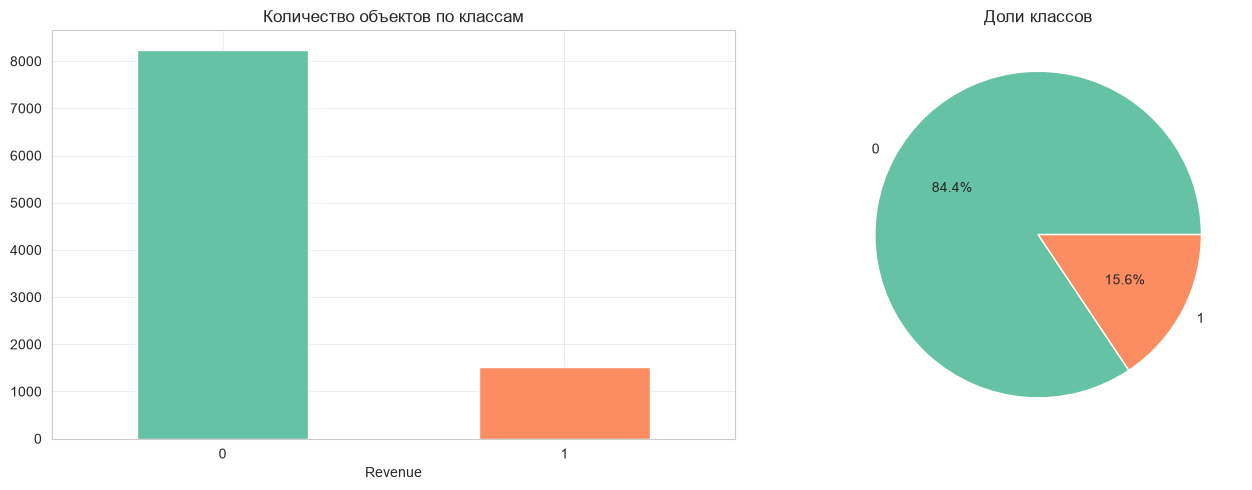

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df[TARGET].value_counts().plot.bar(ax=axes[0], color=sns.color_palette("Set2"))
axes[0].set_title("Количество объектов по классам")
axes[0].tick_params(axis="x", rotation=0)

train_df[TARGET].value_counts(normalize=True).plot.pie(
    ax=axes[1], autopct="%1.1f%%", colors=sns.color_palette("Set2")
)
axes[1].set_ylabel("")
axes[1].set_title("Доли классов")
plt.tight_layout()
plt.show()

Наблюдается сильный дисбаланс классов, отрицательный класс больше - то есть больше сессий, когда пользователи не совершали покупки.

### 1.6 Распределения числовых признаков

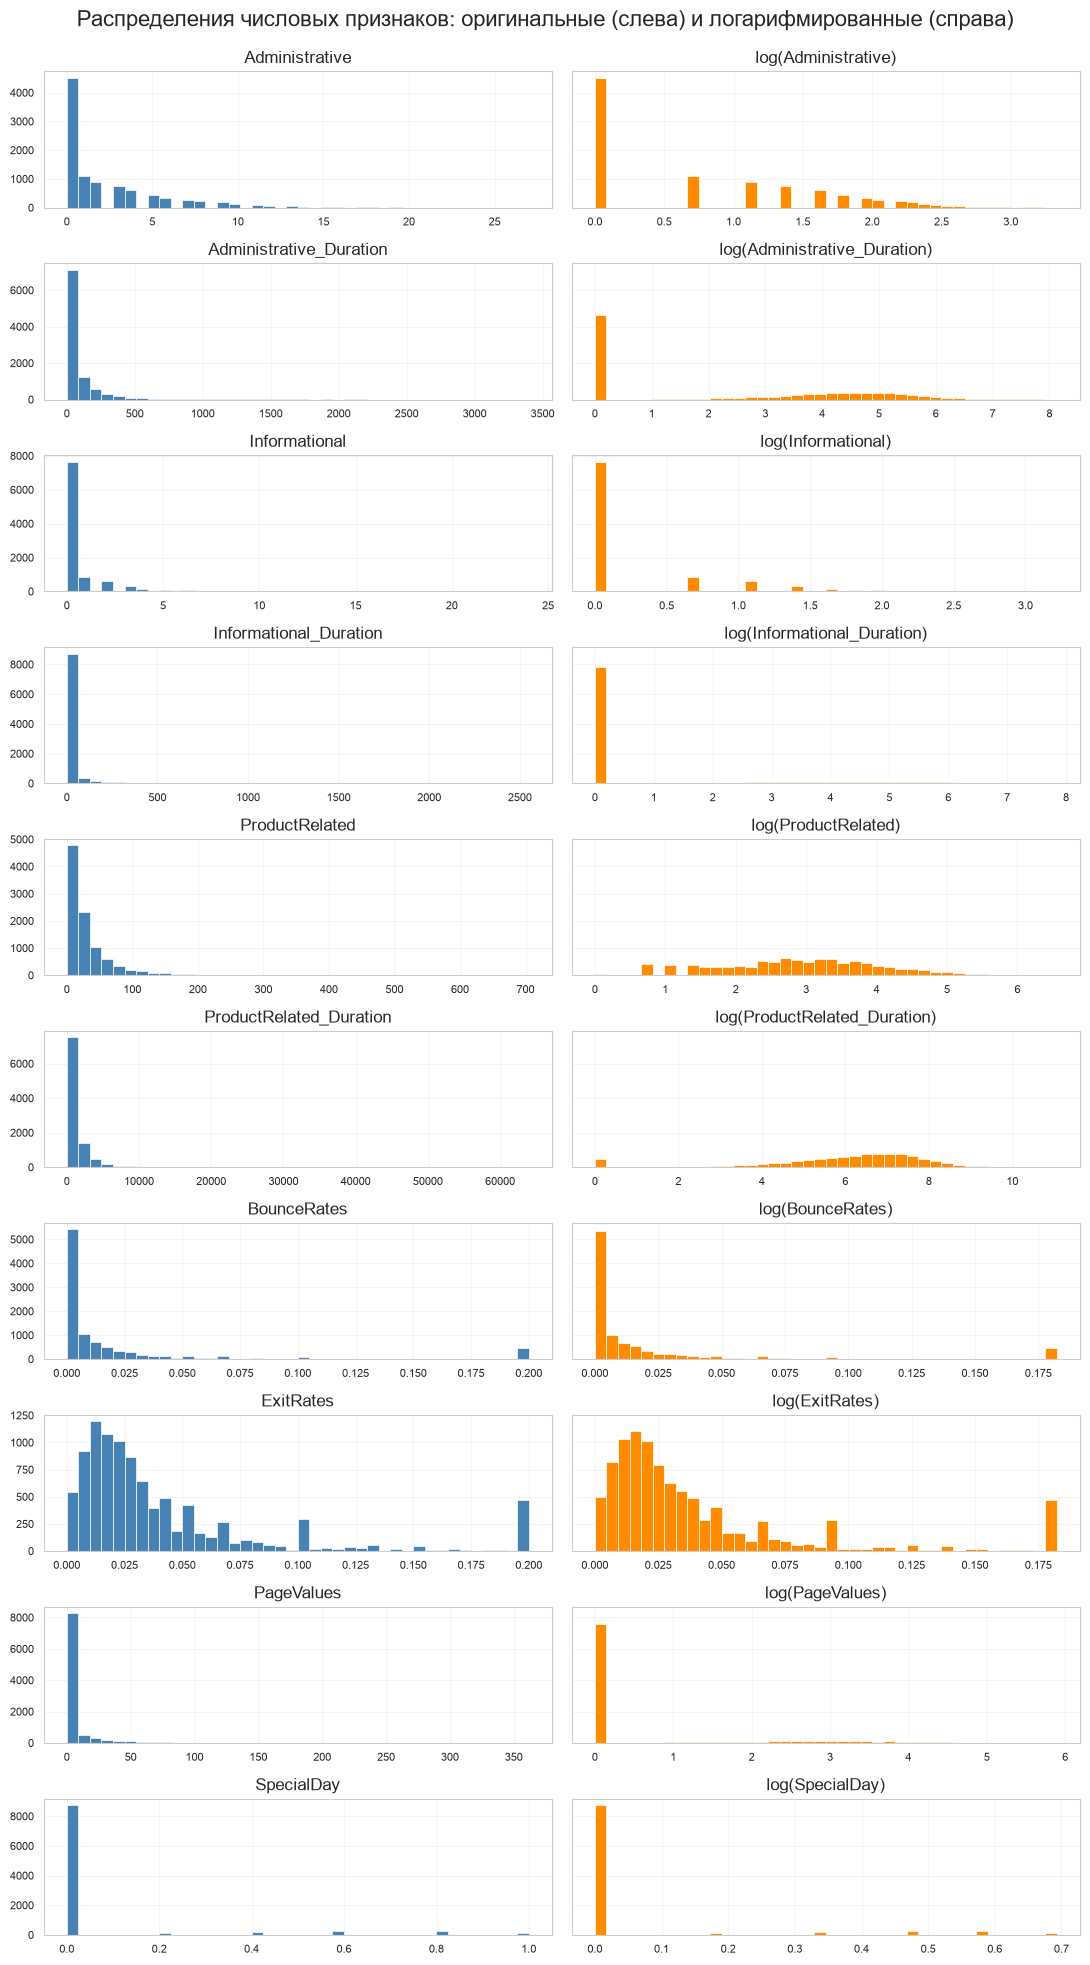

In [15]:
RAW_COLOR, LOG_COLOR = "steelblue", "darkorange"

n_rows = len(NUM_COLS)
fig, axes = plt.subplots(n_rows, 2, figsize=(11, n_rows * 2.0), sharey="row")

for i, col in enumerate(NUM_COLS):
    raw, logged = train_df[col], np.log1p(train_df[col])

    axes[i, 0].hist(raw, bins=40, color=RAW_COLOR, edgecolor="white", linewidth=0.5)
    axes[i, 0].set_title(f"{col}", fontsize=12)

    axes[i, 1].hist(logged, bins=40, color=LOG_COLOR, edgecolor="white", linewidth=0.5)
    axes[i, 1].set_title(f"log({col})", fontsize=12)

    for ax in axes[i]:
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.3)

fig.suptitle(
    "Распределения числовых признаков: оригинальные (слева) и логарифмированные (справа)",
    fontsize=16,
)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

In [16]:
pd.DataFrame(
    {
        "асимметрия": train_df[NUM_COLS].skew(),
        "асимметрия после логарифмирования": np.log1p(train_df[NUM_COLS]).skew(),
        "доля нулей": (train_df[NUM_COLS] == 0).mean(),
    }
).round(2).sort_values("асимметрия", ascending=False)

,асимметрия,асимметрия после логарифмирования,доля нулей
ProductRelated_Duration,7.87,-1.43,0.05
Informational_Duration,7.54,1.91,0.80
PageValues,6.55,1.80,0.78
Administrative_Duration,5.68,0.24,0.47
ProductRelated,4.39,-0.04,0.00
Informational,4.10,2.01,0.78
SpecialDay,3.27,3.09,0.90
BounceRates,3.17,3.09,0.45
ExitRates,2.24,2.13,0.01
Administrative,1.99,0.56,0.46


Графики распределений числовых признаков и таблица асимметрии и доли нулей показывают следующее. Все десять признаков скошены вправо (асимметрия от 2 до 8). 

У переменных `Administrative`, `Administrative_Duration`, `ProductRelated`, `ProductRelated_Duration` такая асимметрия обусловлена тяжелым правым хвостом, что улучшается логарифмированием (асимметрия: 1.99 -> 0.56, 5.68 -> 0.24, 4.39 -> -0.04, 7.87 -> -1.43 соответственно). При этом распределение `Administrative_Duration` стало двугорбым (пик в 0 остается, добавился пик в значениях 4-5).

Переменным `Informational`, `Informational_Duration`, `PageValues` логарифм сжал хвост, но пик в нуле по-прежнему остался высоким (доля нулей ~0.8), а значений в хвосте очень мало. Гипотеза: эти переменные стоит бинаризовать (зашел на страницу (значение >0), не зашел на страницу (значение = 0)).

Для переменных `BounceRates`, `ExitRates`, `SpecialDay` логарифм, как и ожидалось, не сработал. 

Однако у переменных `BounceRates` и `SpecialDay` распределения сильно скошены вправо, а также много значений сосредоточено в 0 (для `SpecialDay` доля нулей составляет 0.9, а для `BounceRates` - 0.45, что почти половина). Гипотеза: эти две переменные также стоит бинаризовать.

—————————

Гипотеза: эти преобразования повысят качество предсказаний логистической регресии.

### 1.7 Числовые признаки в разрезе классов

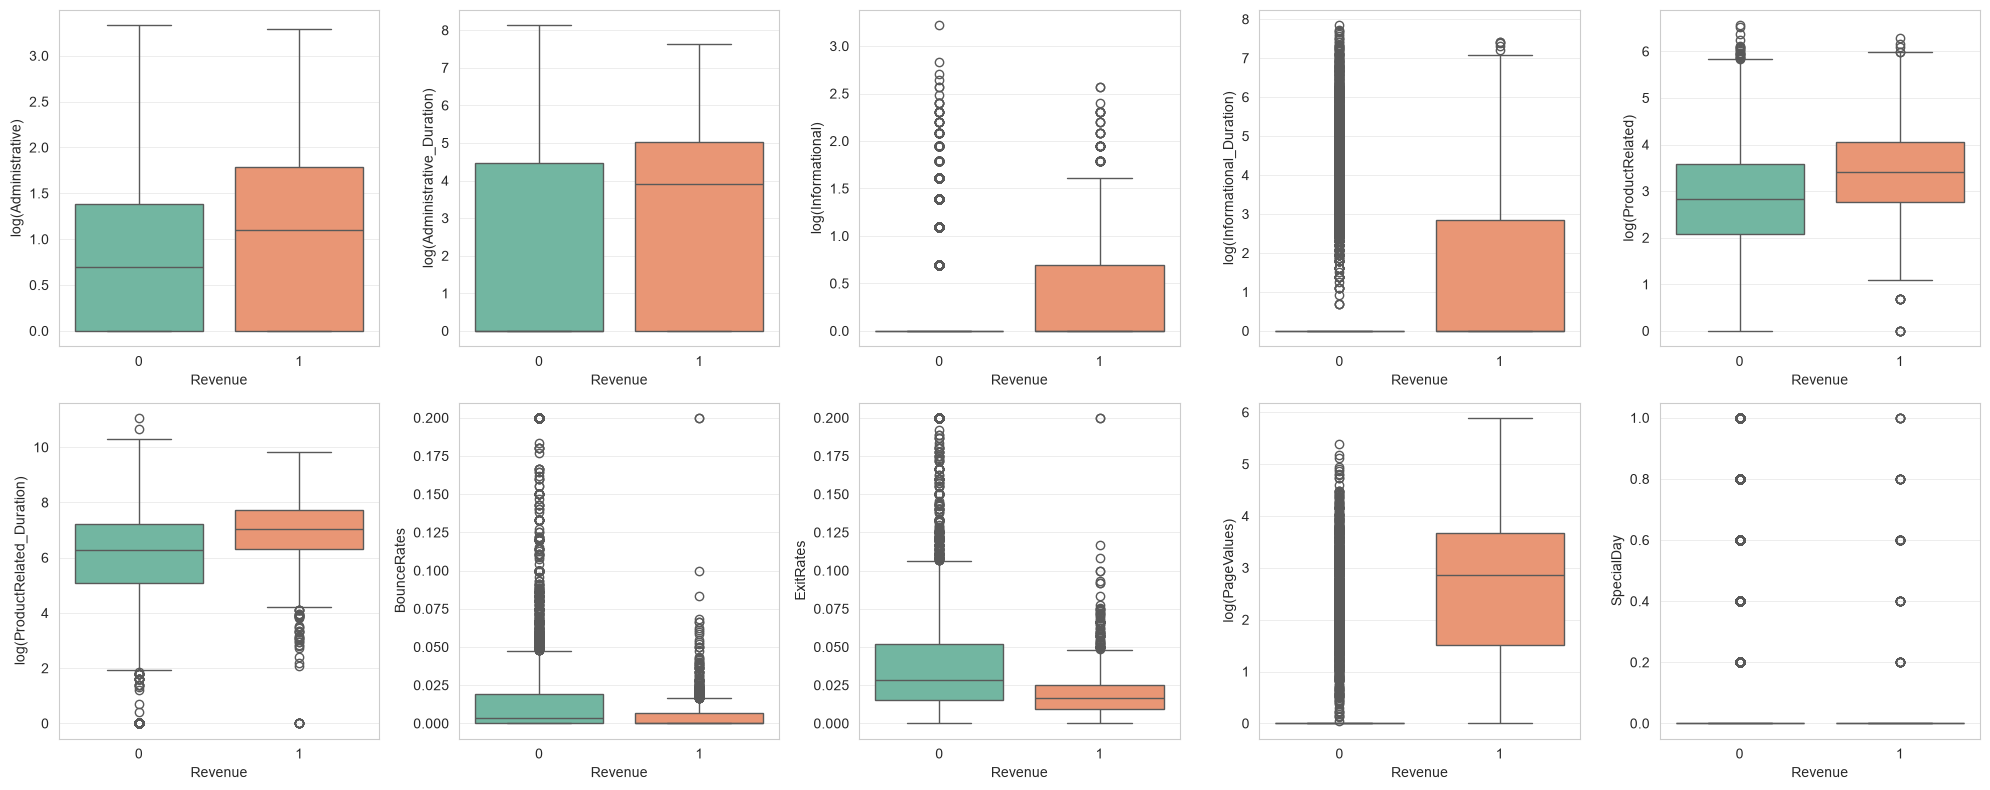

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for idx, col in enumerate(NUM_COLS):
    ax = axes[idx // 5][idx % 5]
    values = np.log1p(train_df[col]) if col in SKEWED_COLS else train_df[col]
    sns.boxplot(x=train_df[TARGET], y=values, ax=ax, palette="Set2")
    ax.set_ylabel(f"log({col})" if col in SKEWED_COLS else col)
plt.tight_layout()
plt.show()

In [18]:
train_df.groupby(train_df["PageValues"] > 0)[TARGET].agg(["mean", "size"]).rename(
    columns={"mean": "доля покупок", "size": "сессий"}
)

,доля покупок,сессий
PageValues,,
False,0.03933,7577
True,0.56150,2187


Боксплоты дают нам следующую связь переменных с таргетом. Предполагается, что самым информативным признаком будет `PageValues` - средняя ценность посещенных страниц. Класс 0 (покупки не было) вырожден в 0, все ненулевые значения помечены как выбросы. В то же время значения положительного класса выше 0, медиана равна ~2.9, выбросов не наблюдается. Эту гипотезу подтверждает и таблица распределения классов в зависимости от того больше ли 0 значение `PageValues`. Доля покупок при `PageValues` > 0 равняется 56%, при `PageValues` < 0 - 3.9%.

Вторым информативным признаком может быть `Administrative_Duration`, у отрицательного класса медиана лежит в 0, то есть пользователь ни секунды не провел на служебных страницах. У положительного класса медиана 3.9. Верхняя граница у этого признака отличается слабо, но учитывая различия в нижней части распределения, может быть важен сам факт захода, то есть эту переменную также стоит бинаризовать.

У обоих классов переменной `ProductRelated` максимальные значения почти одинаковые, однако медианы разные, у положительного класса медиана несколько выше (3.4 против 2.8), нижний квартиль положительного класса равен медиане отрицательного класса. У положительного класса нулевые значения скорее являются выбросами. У признака `ProductRelated_Duration` ситуация похожая: медиана отрицательного класса равна нижнему квартилю положительного. Однако у положительного класса больше 0 значений по сравнению с признаком ProductRelated.

Остальные признаки либо слабо информативны, либо совсем неинформативны, как `SpecialDay` (распределения обоих классов вырождены в 0, все ненулевые значения помечены как выбросы, при этом точки стоят на одних и тех же уровнях).

### 1.8 Корреляции

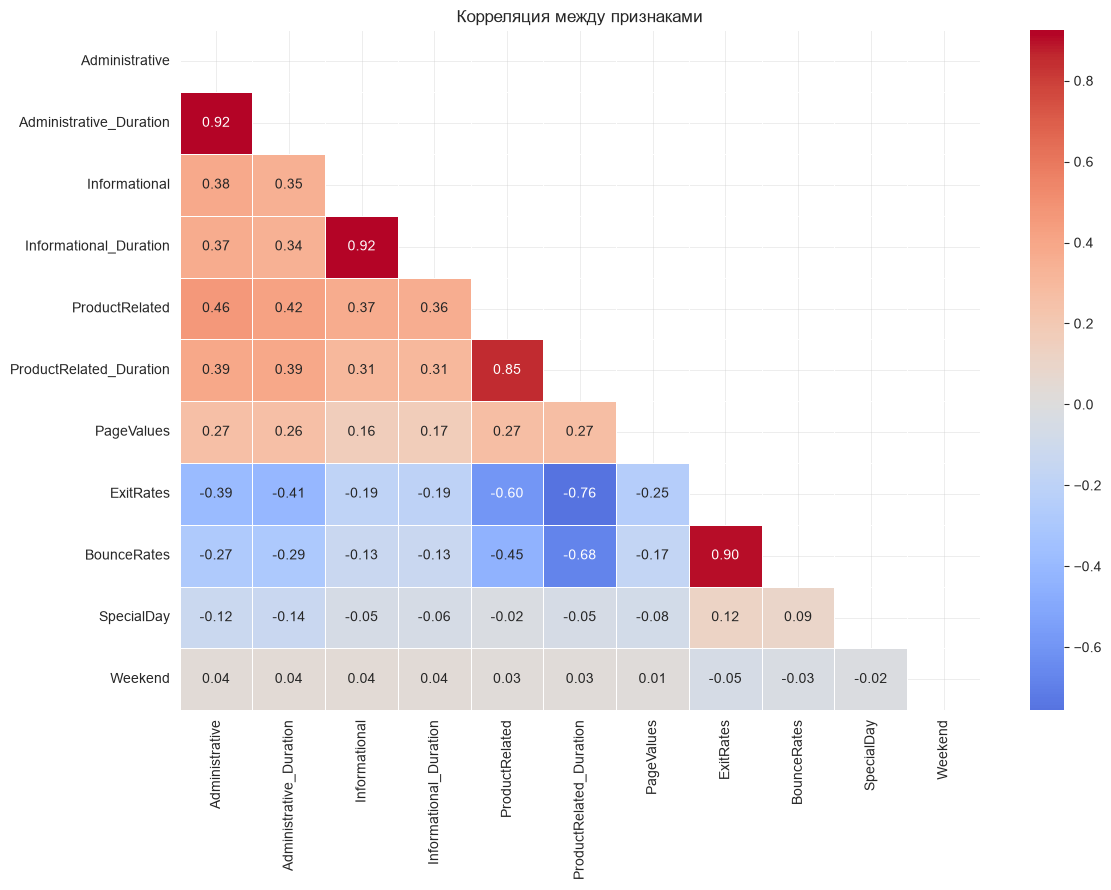

In [19]:
plt.figure(figsize=(12, 9))
corr = pd.concat(
    [
        np.log1p(train_df[SKEWED_COLS]),
        train_df[list(set(NUM_COLS) - set(SKEWED_COLS))],
        train_df[BIN_COLS],
    ],
    axis=1,
).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5
)
plt.title("Корреляция между признаками")
plt.tight_layout()
plt.show()

Наиболее скоррелированными признаками являются пары `ProductRelated` и `ProductRelated_Duration`, `BounceRates` и `ExitRates`, `Administrative` и `Administrative_Duration`, `Informational` и `Informational_Duration`. В целом между признаками, которые связаны с типом посещенных страниц и временем, наблюдается умеренная корреляция.

### 1.9 Категориальные признаки

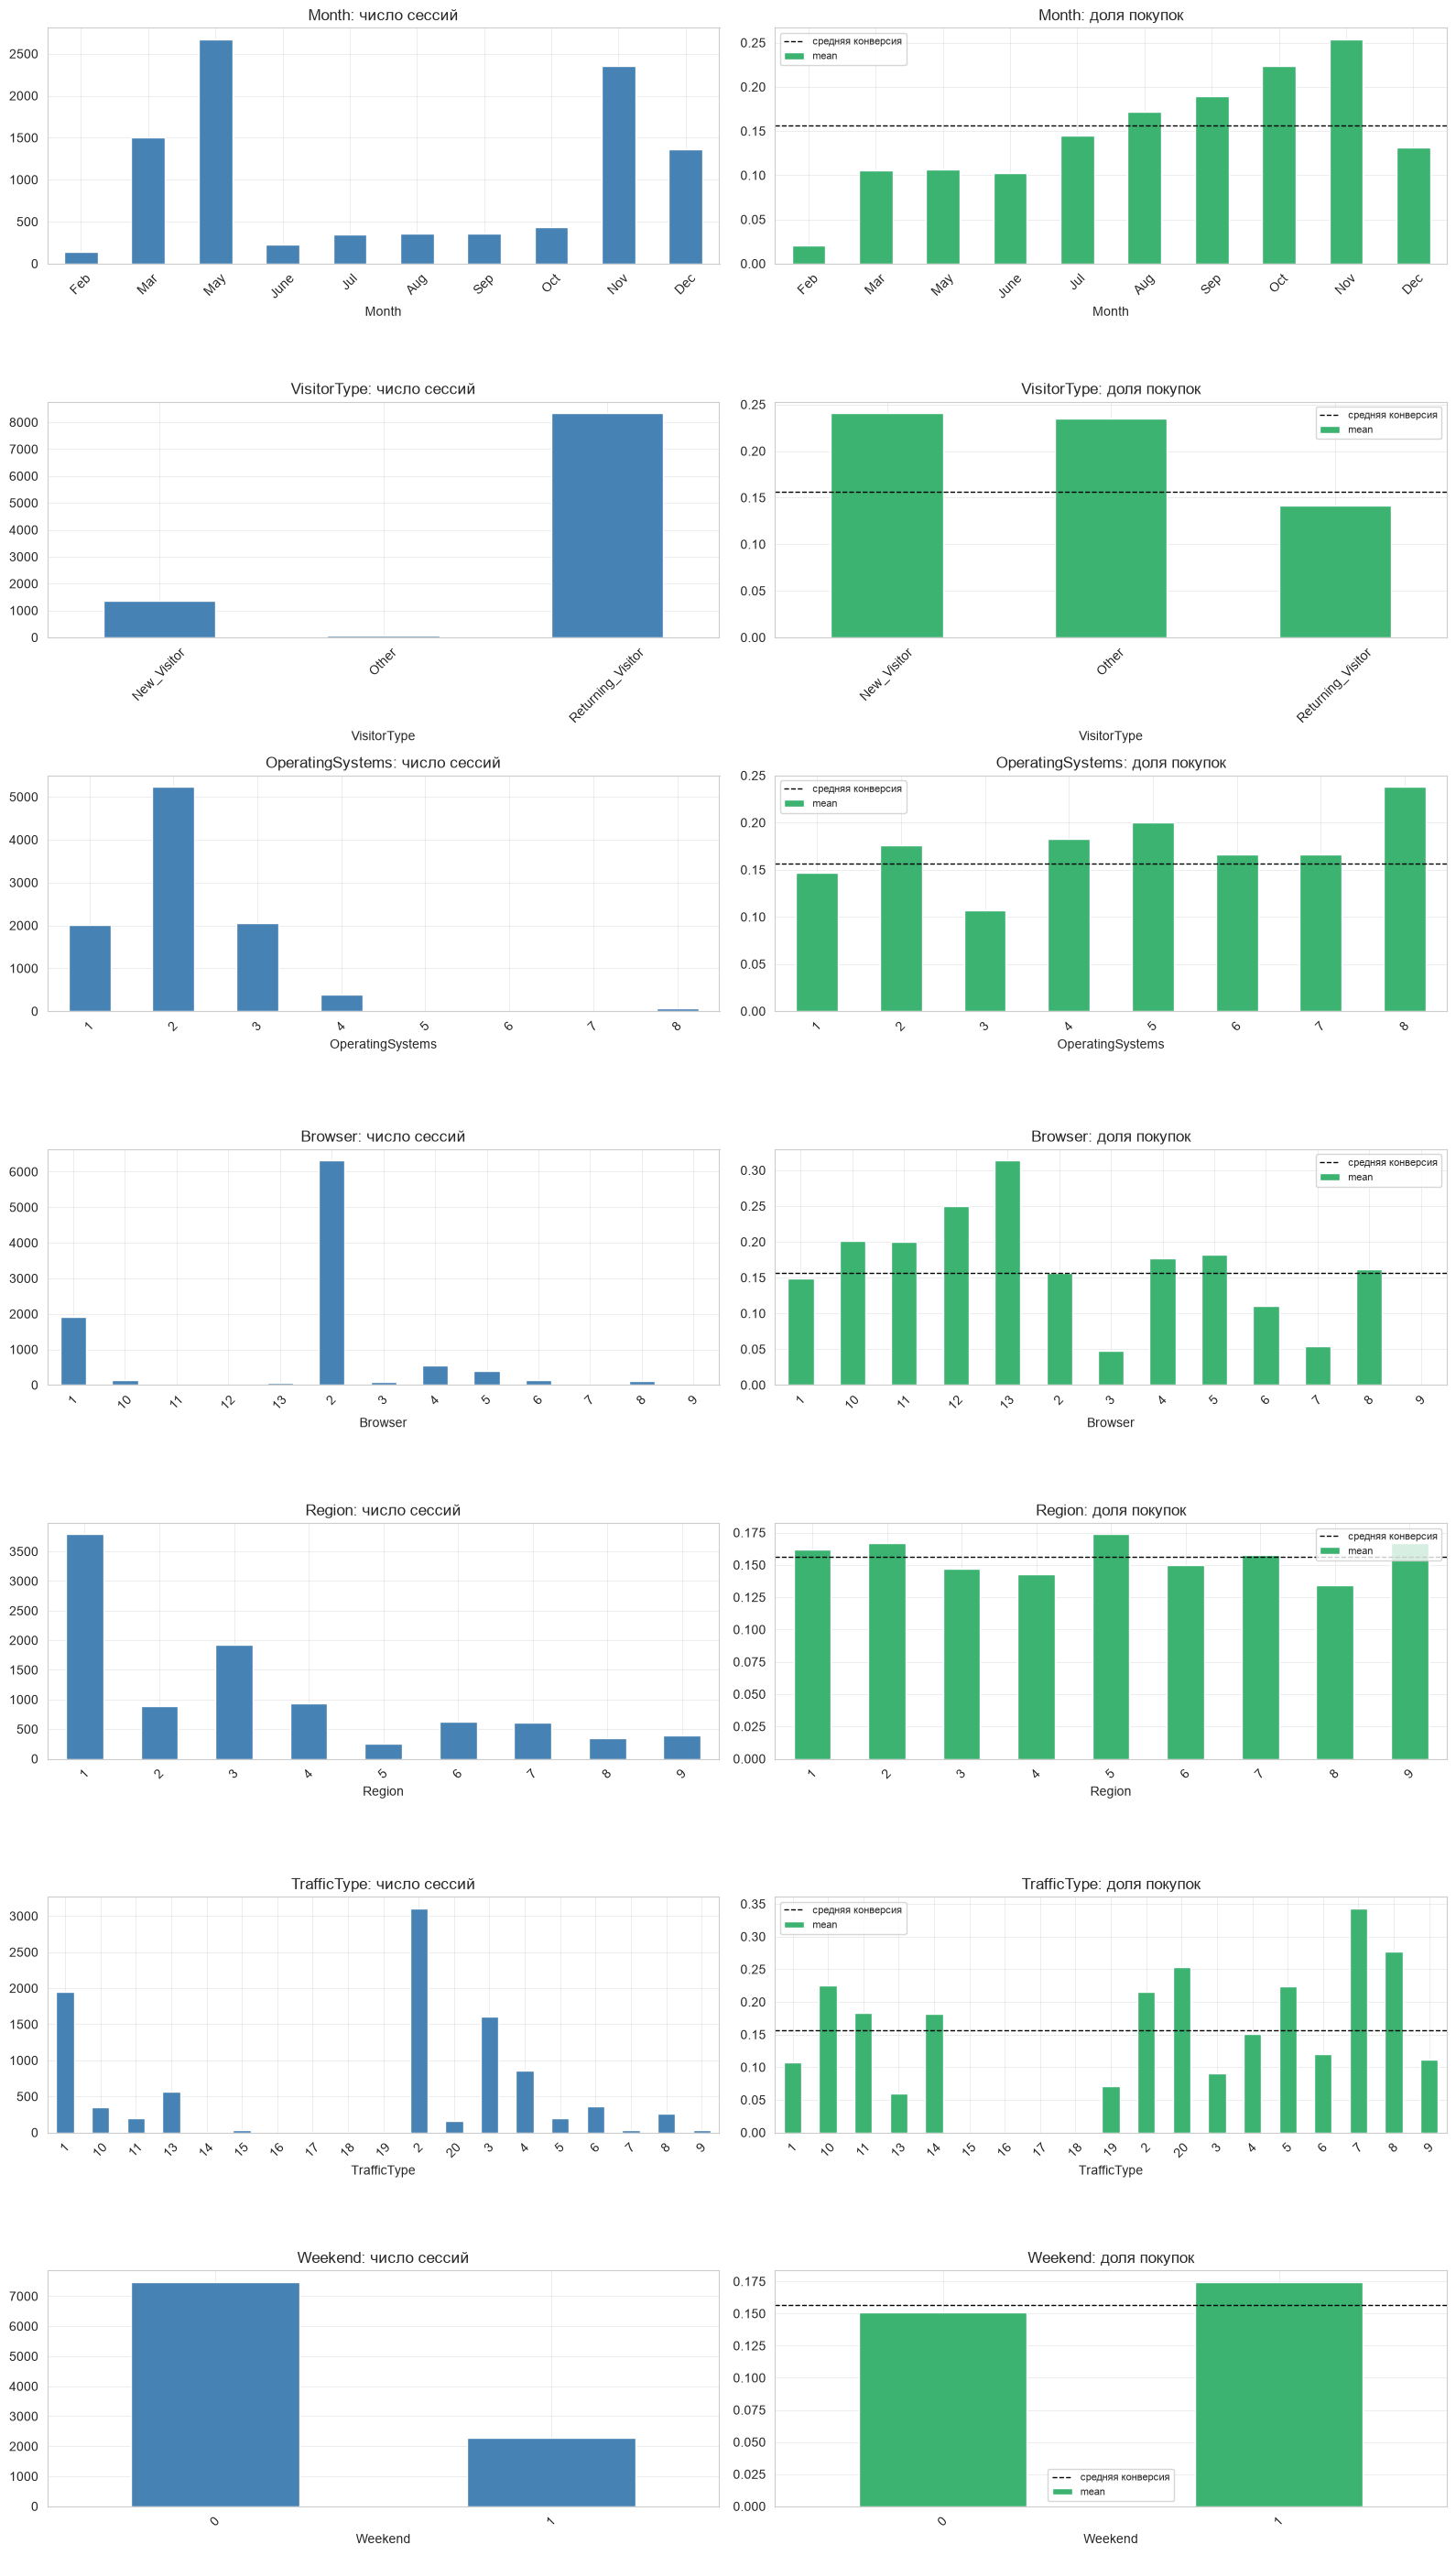

In [20]:
def plot_cat(col, order=None, ax_row=None):
    stats = train_df.groupby(col)[TARGET].agg(["size", "mean"])
    if order is not None:
        stats = stats.reindex([o for o in order if o in stats.index])
    stats["size"].plot.bar(ax=ax_row[0], color="steelblue")
    ax_row[0].set_title(f"{col}: число сессий")
    stats["mean"].plot.bar(ax=ax_row[1], color="mediumseagreen")
    ax_row[1].axhline(
        y_train.mean(), color="k", ls="--", lw=1, label="средняя конверсия"
    )
    ax_row[1].set_title(f"{col}: доля покупок")
    ax_row[1].legend(fontsize=8)
    for ax in ax_row:
        ax.tick_params(axis="x", rotation=45)


fig, axes = plt.subplots(len(CAT_COLS) + 1, 2, figsize=(16, 4 * (len(CAT_COLS) + 1)))
for i, col in enumerate(CAT_COLS + BIN_COLS):
    plot_cat(col, order=MONTH_ORDER if col == "Month" else None, ax_row=axes[i])
plt.tight_layout()
plt.show()

In [21]:
pd.crosstab(train_df["Month"], train_df["SpecialDay"]).reindex(MONTH_ORDER)

SpecialDay,0.0,0.2,0.4,0.6,0.8,1.0
Month,,,,,,
Feb,80,13,13,17,16,5
Mar,1500,0,0,0,0,0
May,1730,128,189,267,242,118
June,225,0,0,0,0,0
Jul,353,0,0,0,0,0
Aug,360,0,0,0,0,0
Sep,354,0,0,0,0,0
Oct,433,0,0,0,0,0
Nov,2358,0,0,0,0,0


Признак `Month` распределен очень неравномерно, больше всего сессий наблюдается в мае, ноябре, марте и декабре, в остальные месяцы посетителей немного. В ноябре доля покупок выше всего, скорее всего это объясняется черной пятницей и близостью к новогодним праздникам. В мае больше всего сессий, но при этом доля покупок довольно низкая (всего 0.11). Февраль и май являются месяцами, в которые также присутствуют праздники, однако доля покупок в эти месяцы низкая, это может объяснить, почему признак `SpecialDay` неинформативный. Также согласно таблице выше, праздники есть только в феврале и мае. Опять же подтверждение, что признак `SpecialDay` бесполезный.

В признаке `VisitorType` наибольший класс - это заядлые посетители, новых посетителей в разы меньше, однако доля покупок и новых посетителей больше. 

Категории 4, 5, 6, 7, 8 в переменной `OperatingSystems` слишком малочисленны, чтобы делать какие-то выводы по доле покупок. Гипотеза: объединить их в одну категорию. Больше всего пользователей с операционной системой 2, конверсия у них также выше средней.  ОС 1 и 3 пользуются меньше пользователей, конверсия у них ниже средней.

Признак `Browser` имеет только две категории, которые могут быть информативны - 2 и 1, конверсия небольшая - всего ~0.15. Гипотеза: признак почти бесполезен, отбор признаков его уберет.

`Region` самый малоинформативный признак - доля покупок в нем у всех классов примерно одинаковая, при этом низкая - ~0.15. Гипотеза: отбор признаков уберет этот признак.

В признаке `TrafficType` много малочисленных категорий, также есть категории с отсутствием покупок. Доля покупок по типу источника траффика распределена неравномерно. Эти факты свидетельствуют о том, что типы траффика разные по качеству, соответственно, тип трафика влияет и на то, попадет ли вообще пользователь на сайт магазина, и на то, совершит ли он покупку. Тип траффика 2 самый многочисленный, а также в нем конверсия выше средней (0.20).

Признак `Weekend` имеет следующее распределение: в будни 7400 сессий с конверсией 0.149, в выходные 2350 с долей покупок 0.172.

————-

Гипотеза: из категориальных признаков значимы только `TrafficType`, `Month` и `VisitorType`, отбор признаков удалит остальные признаки.

### 1.10 Pairplot ключевых признаков

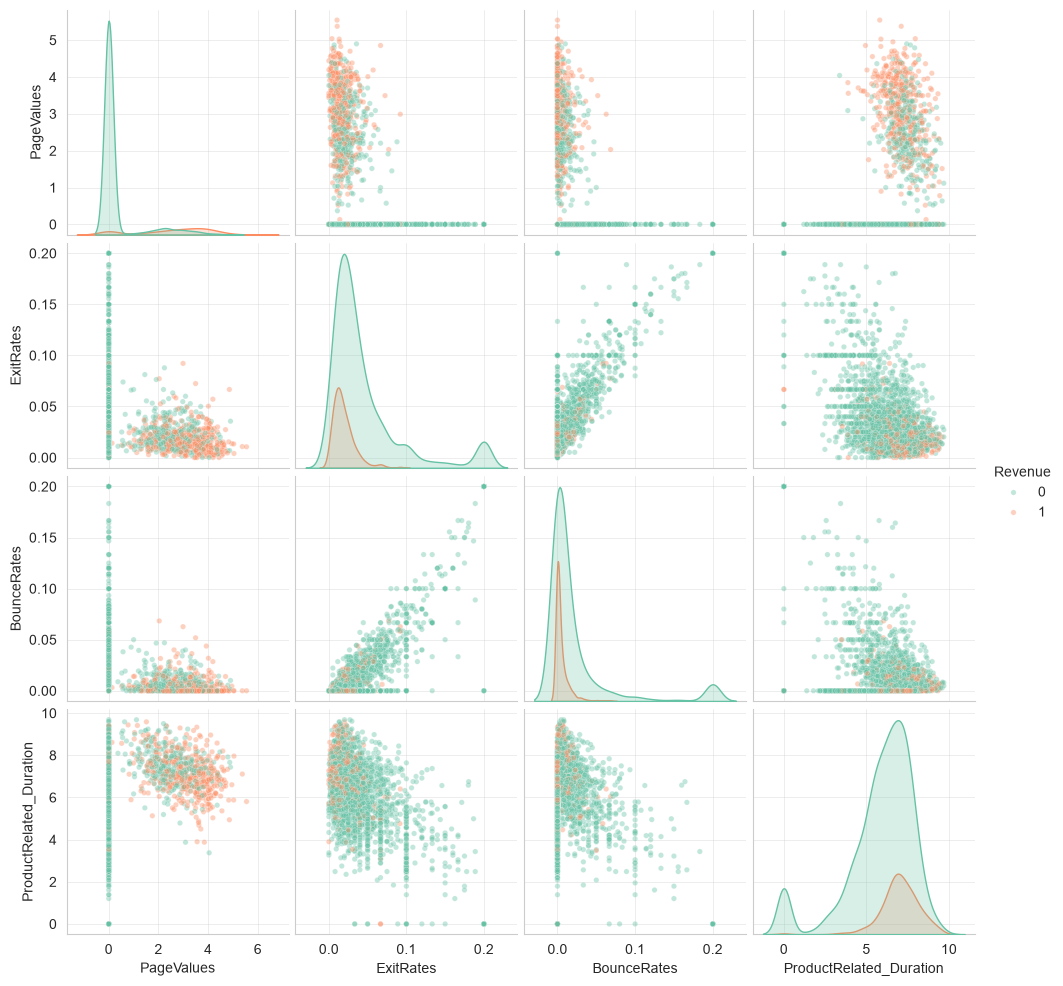

In [22]:
key = ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]
plot_df = train_df[key + [TARGET]].copy()
plot_df[["PageValues", "ProductRelated_Duration"]] = np.log1p(
    plot_df[["PageValues", "ProductRelated_Duration"]]
)
sns.pairplot(
    plot_df.sample(3000, random_state=SEED),
    hue=TARGET,
    palette="Set2",
    plot_kws={"alpha": 0.4, "s": 15},
)
plt.show()

Графики Pairplot показывают, что у всех переменных классы перемешаны, четких границ нет. 

----------

Гипотеза: логистическая регрессия на таких данных будет работать плохо, методы на основе деревьев будут работать лучше.

### Выводы по EDA
1. **Дисбаланс классов:** в данных наблюдается явный дисбаланс классов, отрицательный класс сильно больше положительного. Accuracy не подходит как основная метрика. Основная метрика - PR-AUC, дополнительно ROC-AUC, F1, precision, recall. Разбиение и кросс-валидация исключительно стратифицированные, иначе доля покупок будет неравномерно распределена от фолда к фолду.

2. **Пропуски / дубликаты:** пропусков нет ни в одной из 18 колонок, отрицательных значений в числовых признаках также нет. Полных дубликатов 125, однако это не техническое дублирование: каждая строка - это сессия, причем каждая сессия принадлежит одному пользователю. Дублирование объясняется вырожденностью пространства признаков. Тем не менее дубликаты удалены до разбиения, так как одинаковые векторы в train и test дали бы утечку данных и завышенные метрики.

3. **Распределения:** все 10 числовых признаков скошены вправо. В переменной `ProductRelated_Duration` есть явный выброс - 63974 секунды (около 18 часов). Из анализа распределений вытекает две гипотезы: 1) логарифмирование значений переменных счетчиков и длительностей (`Administrative`, `Administrative_Duration`, `ProductRelated`, `ProductRelated_Duration`) улучшит качество логистической регрессии и не изменит качества методов, основанных на деревьях. 2) Бинаризация (флаги "значение больше 0") признаков `PageValues`, `Informational`, `InformationalDuration`, `BounceRates` и `SpecialDay` даст дополнительный прирост в качестве, потому что у этих признаков сигнал пороговый.

4. **Коррелированные пары:** есть сильноскоррелированные пары признаков (`ProductRelated` и `ProductRelated_Duration`, `BounceRates` и `ExitRates`, `Administrative` и `Administrative_Duration`, `Informational` и `Informational_Duration`). Эта скоррелированность интуитивно понятна: время, проведенное на страницах определенного типа связано с количеством посещенных страниц определенного типа (то есть время не может быть нулевым, если страниц определенного типа вообще не открывали). Гипотеза 1: коэффициенты внутри пары нельзя интерпретировать по-отдельности, отбор признаков внутри пары будет неустойчивым, а permutation importance занизит важность обоих признаков, поскольку модель компенсирует один через другой. Гипотеза 2: вместо удаления одного признака из пары корректнее заменить базис. Пара (Count, Duration) превратится в пару (Count, Duration / Count), то есть второй признак станет средним временем, проведенном на одной странице. Гипотеза 3: Скоррелированность признаков `BounceRates` и `ExitRates` уменьшится путем того, что признак `BounceRates` станет бинарным.

5. **Наиболее связанные с таргетом признаки:** `PageValues` самый информативный признак, самый неинформативный - `SpecialDay`.

6. **Категориальные признаки:** `TrafficType` самый информативный признак среди категориальных, менее информативными являются `Month` и `VisitorType`, отбор признаков удалит остальные признаки. В категориальных признаках очень много редких категорий, которые стоит объединять, чтобы не нарваться на проклятие размерности.

## 2. Добавление признаков

In [23]:
FLAG_BASE = [
    "PageValues",
    "Informational",
    "Administrative",
    "BounceRates",
    "SpecialDay",
]
FLAG_COLS = [f"has_{c}" for c in FLAG_BASE]
FLAGS_MAIN = ["has_PageValues", "has_Informational", "has_SpecialDay"]
AVG_COLS = [f"{c}_avg_time" for c in COUNT_COLS]


def add_features(X):
    X = X.copy()
    for c in FLAG_BASE:
        X[f"has_{c}"] = (X[c] > 0).astype(int)
    for c in COUNT_COLS:
        X[f"{c}_avg_time"] = np.where(
            X[c] > 0, X[f"{c}_Duration"] / X[c].replace(0, np.nan), 0.0
        )
    return X


FE = FunctionTransformer(add_features, validate=False)

In [24]:
add_features(X_train)[FLAG_COLS + AVG_COLS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
has_PageValues,9764.0,0.224,0.417,0.0,0.000,0.000,0.000,1.0
has_Informational,9764.0,0.216,0.411,0.0,0.000,0.000,0.000,1.0
has_Administrative,9764.0,0.537,0.499,0.0,0.000,1.000,1.000,1.0
has_BounceRates,9764.0,0.547,0.498,0.0,0.000,1.000,1.000,1.0
has_SpecialDay,9764.0,0.103,0.304,0.0,0.000,0.000,0.000,1.0
Administrative_avg_time,9764.0,20.563,47.122,0.0,0.000,5.793,24.504,1566.6
Informational_avg_time,9764.0,14.884,65.985,0.0,0.000,0.000,0.000,1778.0
ProductRelated_avg_time,9764.0,38.378,46.986,0.0,17.967,29.290,45.666,1411.0


## 3. Предобработка

Предобработка данных реализована в виде пайплайна, включающего этап генерации новых признаков, выбор варианта представления данных и преобразование признаков перед подачей в модель:
1. Функция `add_features()` добавляет новые признаки в данные. Для части числовых признаков (`PageValues`, `Informational`, `Administrative`, `BounceRates`, `SpecialDay`) создаются бинарные признаки `has_*` (разделение по x_i > 0). Кроме того, для признаков, показывающих время, проведенное за просмотром определенного типа страниц (`Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration`), рассчитывается среднее время, потраченное на одну страницу (`*_avg_time`), как отношение длительности к количеству страниц (признаки `Administrative`, `Informational`, `ProductRelated`). При нулевом количестве страниц среднее время устанавливается равным 0.

2. После добавления признаков `ColumnTransformer` распределяет колонки по нескольким веткам обработки. Числовые признаки, для которых предполагается логарифмическое преобразование, сначала очищаются от пропусков с помощью медианного значения (в данных пропусков нет, это сделано на всякий случай), затем преобразуются функцией `log1p` и стандартизируются с помощью `StandardScaler`. Для остальных числовых признаков выполняется только заполнение пропусков медианой (при необходимости) и стандартизация. Логарифмическое преобразование применяется к скошенным признакам, в частности к количествам страниц, `PageValues`, длительностям и, в вариантах с заменой длительностей, к признакам среднего времени.

3. Категориальные признаки (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`) обрабатываются отдельно: пропущенные значения заменяются наиболее часто встречающейся категорией, после чего выполняется one-hot encoding. При этом редкие категории объединяются в специальную категорию с помощью параметра `min_frequency`, а новые категории, встретившиеся только в тестовых данных, обрабатываются через `handle_unknown='infrequent_if_exist'`. Бинарные признаки `Weekend` и созданные `has_*` уже находятся в нужном формате 0/1, поэтому передаются дальше без дополнительного преобразования (`passthrough`).

Набор `VARIANTS` задает несколько альтернативных схем представления признаков, которые используются для проверки различных гипотез. В `raw` сохраняются исходные числовые признаки без логарифмирования и дополнительных флагов. `log` добавляет логарифмическое преобразование скошенных признаков. `log+flags` дополнительно использует бинарные признаки наличия. В `basis` исходные признаки длительности заменяются на признаки среднего времени на просмотр страницы. В `bounce_flag` исходный `BounceRates` заменяется бинарным `has_BounceRates`. Вариант `all` объединяет эти преобразования: сохраняет количества страниц и среднее время на просмотр страницы, логарифмирует соответствующие признаки, сохраняет `ExitRates` и `SpecialDay`, а `BounceRates` заменяет бинарным флагом.

------------

**Общая схема предобработки:**

```text
                  Исходные данные
                         |
          --------------------------------
          |      Feature Engineering     |
          |                              |
          | * has_* -> бинарные признаки |
          | * avg_time -> Duration/Count |
          --------------------------------
                         |
              Выбор варианта VARIANTS
                         |
          --------------------------------
          |         |          |         |
       Числовые  Числовые  Категории  Бинарные
        + log     без log      |         |
          |         |          |         |
       median     median   most_freq  passthrough
          |         |          |         |
        log1p       |         OHE        |
          |         |          |         |
       scaling   scaling       |         |
          |         |          |         |
          --------------------------------
                         |
           Объединенная матрица признаков
                         |
                 Feature Selection
                         |
                       Model

```

In [25]:
LOG_ALWAYS = COUNT_COLS + ["PageValues"]

VARIANTS = {
    "raw": dict(num=NUM_COLS, log=[], flags=[]),
    "log": dict(num=NUM_COLS, log=LOG_ALWAYS + DUR_COLS, flags=[]),
    "log+flags": dict(num=NUM_COLS, log=LOG_ALWAYS + DUR_COLS, flags=FLAGS_MAIN),
    "basis": dict(
        num=COUNT_COLS + AVG_COLS + RATE_COLS + OTHER_NUM,
        log=LOG_ALWAYS + AVG_COLS,
        flags=FLAGS_MAIN,
    ),
    "bounce_flag": dict(
        num=[c for c in NUM_COLS if c != "BounceRates"],
        log=LOG_ALWAYS + DUR_COLS,
        flags=FLAGS_MAIN + ["has_BounceRates"],
    ),
    "all": dict(
        num=[
            "Administrative",
            "ProductRelated",
            "Administrative_avg_time",
            "Informational_avg_time",
            "ProductRelated_avg_time",
            "ExitRates",
        ],
        log=[
            "Administrative",
            "ProductRelated",
            "Administrative_avg_time",
            "Informational_avg_time",
            "ProductRelated_avg_time",
        ],
        flags=[
            "has_PageValues",
            "has_Informational",
            "has_SpecialDay",
            "has_BounceRates",
        ],
    ),
}


def make_preprocessor(
    variant="log+flags", scale=True, min_frequency=0.01, drop_first=False
):
    cfg = VARIANTS[variant]
    log_cols = [c for c in cfg["num"] if c in cfg["log"]]
    lin_cols = [c for c in cfg["num"] if c not in cfg["log"]]

    def num_steps(with_log):
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if with_log:
            steps.append(
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
            )
        if scale:
            steps.append(("scaler", StandardScaler()))
        return Pipeline(steps)

    ohe = OneHotEncoder(
        handle_unknown="infrequent_if_exist" if min_frequency else "ignore",
        min_frequency=min_frequency,
        drop="first" if drop_first else None,
        sparse_output=False,
    )

    transformers = [
        ("log_num", num_steps(True), log_cols),
        ("num", num_steps(False), lin_cols),
        (
            "cat",
            Pipeline(
                [("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]
            ),
            CAT_COLS,
        ),
        ("bin", "passthrough", BIN_COLS + list(cfg["flags"])),
    ]
    return ColumnTransformer(transformers)


def make_pipe(model, variant="log+flags", selector=None, **prep_kw):
    steps = [("fe", FE), ("prep", make_preprocessor(variant, **prep_kw))]
    if selector is not None:
        steps.append(("sel", selector))
    steps.append(("clf", model))
    return Pipeline(steps)

## 4. Baseline: правиловый метод и логистическая регрессия без регуляризации 

В качестве бейзлайна выступает правиловый метод (`PageValues` > 0), который удалось предположить в рамках EDA. Изначально такой dummy-классификатор будет сравниваться с логистической регрессией без регуляризации и на данных, где числовые признаки не подвергались преобразованиям (кроме скалирования). Это необходимо, чтобы понять, а нужны ли вообще более сложные модели, или же хватает базового правила.

In [26]:
def cv_report(model, X, y, name, cv=CV_OUTER):
    res = cross_validate(
        model, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1
    )
    row = {"model": name}
    for m in SCORING:
        row[m] = res[f"test_{m}"].mean()
    row["AP_std"] = res[f"test_{MAIN_METRIC}"].std()
    row["AP_train"] = res[f"train_{MAIN_METRIC}"].mean()
    return row


results = []

baseline = make_pipe(
    LogisticRegression(penalty=None, max_iter=10000), variant="raw", drop_first=True
)
results.append(
    cv_report(
        baseline, X_train, y_train, "LogReg без регуляризации (оригинальные данные)"
    )
)

# Правило PageValues > 0
rule_pred = (X_train["PageValues"] > 0).astype(int)
results.append(
    {
        "model": "Правило: PageValues > 0",
        "average_precision": average_precision_score(y_train, rule_pred),
        "roc_auc": roc_auc_score(y_train, rule_pred),
        "f1": f1_score(y_train, rule_pred),
        "precision": precision_score(y_train, rule_pred),
        "recall": recall_score(y_train, rule_pred),
        "accuracy": accuracy_score(y_train, rule_pred),
        "AP_std": np.nan,
        "AP_train": np.nan,
    }
)

pd.DataFrame(results).set_index("model").round(3).T

model,LogReg без регуляризации (оригинальные данные),Правило: PageValues > 0
average_precision,0.635,0.482
roc_auc,0.888,0.844
f1,0.497,0.661
precision,0.743,0.561
recall,0.374,0.805
accuracy,0.882,0.871
AP_std,0.022,NaN
AP_train,0.649,NaN


Логистическая регрессия показала более высокие значения Average Precision по сравнению с правиловым методом (0.635 vs 0.482). То есть использование совокупности признаков, а не одного признака `PageValues` позволяет получать более качественное предсказание. Однако для логистической регрессии необходимо подобрать порог. При пороге 0.5, идущем по умолчанию, модель ведет себя осторожнее, чем правиловый метод - модель показала более низкие метрики Recall и F1 (0.374 & 0.497 vs 0.805 & 0.661) по сравнению с правилом. При этом Precision у логистической регрессии оказался выше (0.743 vs 0.561). То есть модель ведет себя более осторожно: среди предсказанных моделью покупателей доля людей, действительно совершивших покупку, выше, но при это модель не обнаруживает значительную часть положительного класса. Более высокие метрики Recall и F1 у правилового метода объясняются тем, что правило `PageValues` > 0 позволяет выявить большую часть объектов положительного класса.  

## 5. Эксперимент 1: варианты предобработки (H4, H6)

В этом блоке проверяются гипотезы H4 и H6, другие преобразования, описанные в гипотезах H5 и H7 дополнительно исследуются, чтобы была более полная картина, хотя напрямую в гипотезах не выдвигается влияние на метрики моделей. Используются две модели, которые в каждом отдельном эксперименте фиксированы, то есть меняется только предобработка признаков. В качестве моделей взяты:

* **логистическая регрессия** - модель для которой проверяется влияние преобразований.
* **решающее дерево** - модель берется в качестве контрольной группы: так как решающее дерево инвариантно к монотонным преобразованиям, то оригинальные данные и логарифмированные числовые признаки должны дать одинаковый результат.

В качестве метрики для сравнения будет использоваться PR-AUC, в качестве критерия значимости будет рассматриваться стандартное отклонение метрики Average Precision по фолдам (чтобы удостовериться, что преобразование дало значимый результат).

In [27]:
exp1 = []
for v in VARIANTS:
    exp1.append(
        cv_report(
            make_pipe(LogisticRegression(max_iter=5000), variant=v, scale=True),
            X_train,
            y_train,
            f"LogReg | {v}",
        )
    )
    exp1.append(
        cv_report(
            make_pipe(
                DecisionTreeClassifier(max_depth=6, random_state=SEED),
                variant=v,
                scale=False,
            ),
            X_train,
            y_train,
            f"Tree | {v}",
        )
    )

exp1_df = pd.DataFrame(exp1).set_index("model")
exp1_df[[MAIN_METRIC, "AP_std", "roc_auc", "f1", "AP_train"]].round(4)

,average_precision,AP_std,roc_auc,f1,AP_train
model,,,,,
LogReg | raw,0.6360,0.0219,0.8889,0.4973,0.6495
Tree | raw,0.6751,0.0277,0.9089,0.6366,0.7828
LogReg | log,0.6828,0.0199,0.9115,0.6167,0.6953
Tree | log,0.6746,0.0272,0.9084,0.6363,0.7828
LogReg | log+flags,0.6948,0.0238,0.9121,0.6407,0.7089
Tree | log+flags,0.6737,0.0252,0.9078,0.6353,0.7828
LogReg | basis,0.6946,0.0237,0.9120,0.6379,0.7085
Tree | basis,0.6740,0.0275,0.9059,0.6287,0.7782
LogReg | bounce_flag,0.6973,0.0234,0.9121,0.6426,0.7106


В качестве бейзлайна для этого эксперимента выступает логистическая регрессия, обученная на данных, где числовые признаки подверглись только скалированию, без других преобразований.

Дерево решений показывает ~ одинаковые метрики, то есть инвариантность к монотонным преобразованиям действительно есть. Также интересно, что дерево решений обходит логистическую регрессию на данных, не подвергшихся преобразованиям (в других случаях наоборот) - 0.68 против 0.64.

-------------

**H4** подтвердилась - логарифмирование дало увеличение метрики PR-AUC (0.68) по сравнению с бейзлайном (0.64), при этом стандартное отклонение PR-AUC для логистической регрессии с логарифмированными признаками в 2 раза меньше, чем разница между двумя сравниваемыми наборами признаков, то есть увеличение значимо. 

----------

**H6** подтвердилась частично - бинаризация признаков действительно дала небольшой прирост PR-AUC (0.69, то есть + 0.012) по сравнению с логарифмированием при стандартном отклонении 0.024, однако эффект недостаточный.

-------

Остальные варианты преобразований нужны для проверки других гипотез, однако результаты стоит рассмотреть.

* Замена базиса для переменных `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` дала значимый результат только по сравнению с бейзлайном, увеличение метрики по сравнению с логарифмированием и бинаризацией незначительное.
* Бинаризация `BounceRates` также не ухудшила качество.
* Все преобразования разом (логарифмирование, замена базиса, бинаризация) также не ухудшили результат (по сравнению с бейзлайном наблюдается увеличение).

## 6. Эксперимент 2: мультиколлинеарность (H5, H7)

В этом эксперименте проверяются гипотезы H5 и H7, связанные с устранением коллинеарности за счет преобразования числовых признаков.

In [28]:
Xf = add_features(X_train)

LOGGED = COUNT_COLS + DUR_COLS + AVG_COLS + ["PageValues"]


def prep_corr(cols):
    Z = Xf[cols].copy()
    for c in cols:
        if c in LOGGED:
            Z[c] = np.log1p(Z[c].clip(lower=0))
    return Z.corr()


BEFORE_COLS = NUM_COLS
AFTER_COLS = COUNT_COLS + AVG_COLS + ["ExitRates", "has_BounceRates"] + OTHER_NUM

corr_before, corr_after = prep_corr(BEFORE_COLS), prep_corr(AFTER_COLS)

rows = []
for cnt in COUNT_COLS:
    rows.append(
        {
            "пара": f"{cnt}, Duration",
            "было": corr_before.loc[cnt, f"{cnt}_Duration"],
            "стало": corr_after.loc[cnt, f"{cnt}_avg_time"],
            "что заменили": f"{cnt}_Duration -> {cnt}_avg_time",
        }
    )
rows.append(
    {
        "пара": "BounceRates, ExitRates",
        "было": corr_before.loc["BounceRates", "ExitRates"],
        "стало": corr_after.loc["has_BounceRates", "ExitRates"],
        "что заменили": "BounceRates -> has_BounceRates (бинаризация)",
    }
)

pairs_df = pd.DataFrame(rows)
pairs_df["изменение"] = pairs_df["стало"].abs() - pairs_df["было"].abs()
pairs_df.round(3)

,пара,было,стало,что заменили,изменение
0,"Administrative, Duration",0.924,0.808,Administrative_Duration -> Administrative_avg_...,-0.116
1,"Informational, Duration",0.916,0.860,Informational_Duration -> Informational_avg_time,-0.056
2,"ProductRelated, Duration",0.852,0.415,ProductRelated_Duration -> ProductRelated_avg_...,-0.437
3,"BounceRates, ExitRates",0.900,0.324,BounceRates -> has_BounceRates (бинаризация),-0.576


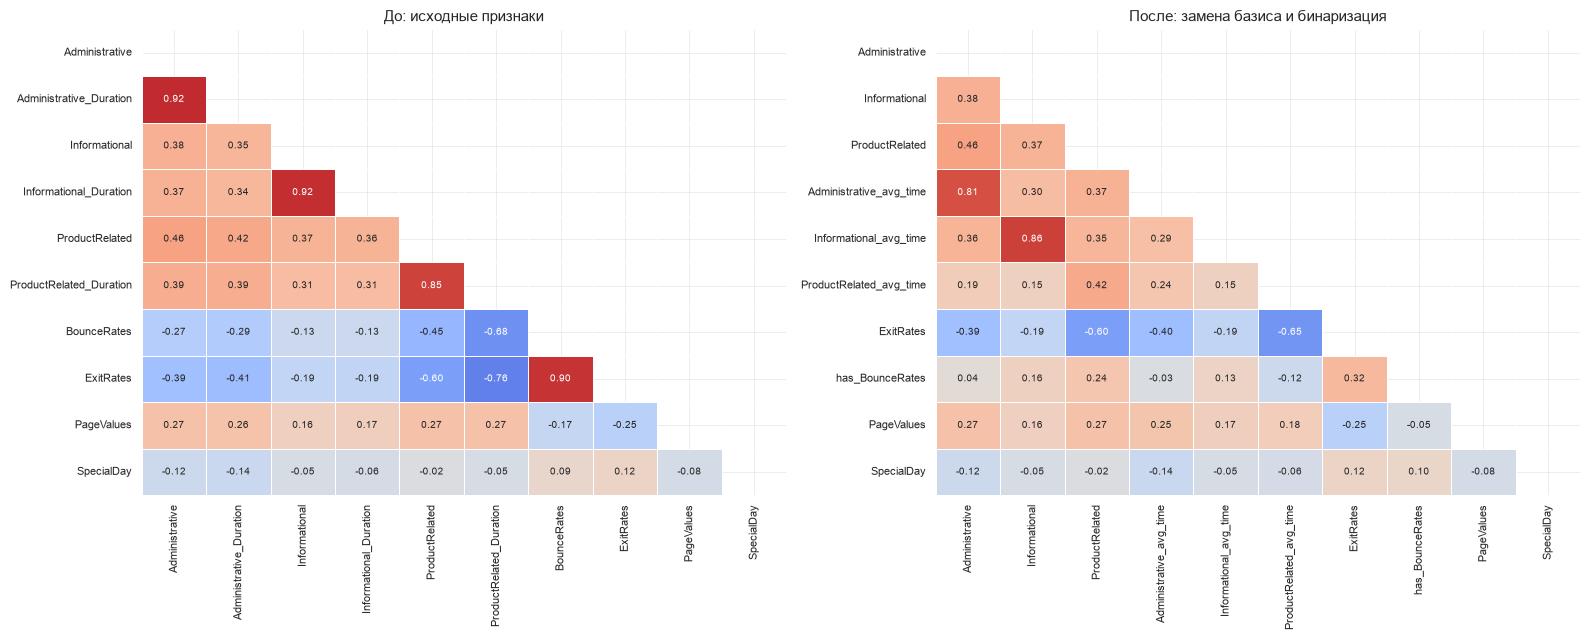

In [29]:
def n_high(c, thr=0.7):
    m = c.abs().where(~np.eye(len(c), dtype=bool))
    return int(m.stack().gt(thr).sum() / 2)


fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, c, title in zip(
    axes,
    [corr_before, corr_after],
    ["До: исходные признаки", "После: замена базиса и бинаризация"],
):
    mask = np.triu(np.ones_like(c, dtype=bool))
    sns.heatmap(
        c,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar=False,
        ax=ax,
        annot_kws={"size": 7},
    )
    mx = c.abs().where(~np.eye(len(c), dtype=bool)).stack()
    ax.set_title(f"{title}", fontsize=11)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

**H7** подтвердилась - бинаризация признака `BounceRates` действительно убрала мультиколлинеарность (коэффициент корреляции был 0.90, стал 0.32). При этом, как выяснилось в эксперименте 1, качество предсказания не пострадало.

Часть гипотезы **H5**, связанная с устранением мультиколлинеарности, подтвердилась частично - замена базиса помогла в случае пары `ProductRelated` и `ProductRelated_Duration`. У переменной `ProductRelated_Duration` доля нулей составляет всего 0.05, в то время как у переменных `Administrative_Duration` и `Informational_Duration` доля нулей составляет 0.47 и 0.80 соответственно. То есть это преобразование дало значимое уменьшение коэффициента корреляции только для счетчиков, где нет большого количества нулей.

## 7. Эксперимент 3: отбор признаков (H1, H2)

Данный раздел посвящен проверке гипотез H1 и H2, связанных с важностью признаков. Отбор признаков осуществляется логистической регрессией на обучающей части каждого набора фолдов. Гипотезы будут проверяться на данных, которые подверглись всем возможным преобразованиям.

Здесь производятся три проверки: сначала сравнивается, нужен ли вообще отбор признаков, и какой способ лучше; затем выясняется, какие признаки остались после отбора, какие у них коэффициенты; наконец, отдельно проверяется гипотеза H2 для категориальных признаков (какие признаки останутся значимыми). Дополнительно проверяется утверждение из EDA о необходимости объединять редкие категории.

In [30]:
BEST_VARIANT = "all"

selectors = {
    "без отбора": (None, {}),
    "фильтр SelectKBest": (
        SelectKBest(f_classif),
        {"sel__k": [5, 10, 15, 20, 25, 30, 35, 40]},
    ),
    "L1 (SelectFromModel)": (
        SelectFromModel(
            LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000)
        ),
        {"sel__estimator__C": [0.01, 0.1, 1]},
    ),
    "RFE": (
        RFE(LogisticRegression(max_iter=5000), step=5),
        {"sel__n_features_to_select": [5, 10, 15, 20, 25, 30, 35, 40]},
    ),
}

sel_rows = []
for name, (sel, grid) in selectors.items():
    pipe = make_pipe(
        LogisticRegression(max_iter=5000), variant=BEST_VARIANT, selector=sel
    )
    full_grid = {**grid, "clf__C": [0.1, 1, 10]}
    search = GridSearchCV(pipe, full_grid, scoring=MAIN_METRIC, cv=CV_INNER, n_jobs=-1)

    s = cross_val_score(
        search, X_train, y_train, scoring=MAIN_METRIC, cv=CV_OUTER, n_jobs=-1
    )
    sel_rows.append({"метод": name, "PR-AUC": s.mean(), "std": s.std()})

pd.DataFrame(sel_rows).set_index("метод").round(4)

,PR-AUC,std
метод,,
без отбора,0.6811,0.0305
фильтр SelectKBest,0.6728,0.0285
L1 (SelectFromModel),0.6831,0.0326
RFE,0.6824,0.0302


Все методы отбора признаков дают одинаковый результат. Также отбор признаков не привел к заметному изменению качества предсказаний логистической регрессии. Средний PR-AUC для всех методов отбора признаков находится в диапазоне 0.6728-0.6831, а различия между ними меньше стандартного отклонения.

L1 регуляризация показала наилучший результат (0.6995), однако различие с моделью без отбора крайне мало и не позволяет говорить о существенном улучшении качества.

**Для анализа признаков будет использоваться метод отбора признаков RFE**, так как он более информативен по сравнению с другими признаками - на каждой итерации алгоритма наименее важные признаки удаляются, после чего модель еще раз обучается, то есть это позволяет учитывать взаимосвязь между признаками.

In [31]:
sel, grid = selectors["RFE"]
pipe = make_pipe(LogisticRegression(max_iter=5000), variant=BEST_VARIANT, selector=sel)
search = GridSearchCV(
    pipe, {**grid, "clf__C": [0.1, 1, 10]}, scoring=MAIN_METRIC, cv=CV_INNER, n_jobs=-1
)
search.fit(X_train, y_train)

best = search.best_estimator_
names = np.array(best["prep"].get_feature_names_out())
support = best["sel"].get_support()
selected, dropped = names[support], names[~support]

print("Лучшие параметры:", search.best_params_)
print(f"До отбора: {len(names)} признаков")
print(f"После отбора: {len(selected)} признаков")

Лучшие параметры: {'clf__C': 0.1, 'sel__n_features_to_select': 25}
До отбора: 58 признаков
После отбора: 25 признаков


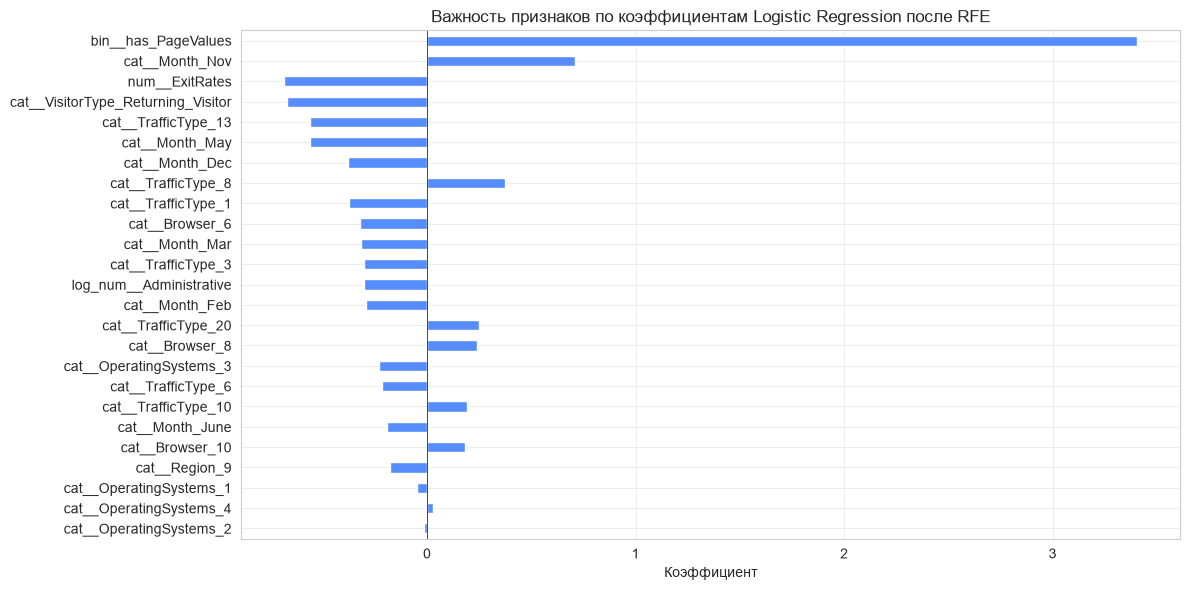

In [32]:
coefs = pd.DataFrame({"RFE": best["clf"].coef_[0]}, index=selected)

coefs["abs_RFE"] = coefs["RFE"].abs()
coefs = coefs.sort_values("abs_RFE")

fig, ax = plt.subplots(figsize=(12, 6))
coefs["RFE"].plot.barh(ax=ax, legend=False)

ax.set_title("Важность признаков по коэффициентам Logistic Regression после RFE")
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Коэффициент")

plt.tight_layout()
plt.show()

In [33]:
def survival(prefix):
    total = sum(n.startswith(f"cat__{prefix}") for n in names)
    kept = sum(n.startswith(f"cat__{prefix}") for n in names[support])
    return {
        "признак": prefix,
        "колонок после OHE": total,
        "осталось": kept,
        "доля удаленных": round(1 - kept / total, 2) if total else np.nan,
    }


pd.DataFrame([survival(p) for p in CAT_COLS])

,признак,колонок после OHE,осталось,доля удаленных
0,Month,10,6,0.40
1,VisitorType,3,1,0.67
2,OperatingSystems,5,4,0.20
3,Browser,8,3,0.62
4,Region,9,1,0.89
5,TrafficType,12,7,0.42


Метод отбора признаков RFE сократил модель с 58 признаков до 25, при этом качество не ухудшилось по сравнению с моделью без отбора признаков.

**H1** подтвердилась, на графике коэффициентов логистической регрессии видно, что `PageValues` (бинаризированный) действительно имеет самый большой коэффициент, а следовательно, в данной модели это самый значимый признак.

**H2** подтвердилась частично - `Month` (осталось 6 категорий из 10), `VisitorType` (1 из 3), `TrafficType` (7 из 12) действительно значимы, однако не все категории переменных `Region` и `Browser` были удалены, то есть часть гипотезы, что отбор признаков удалит все дамми-колонки `Region` и `Browser`, не подтвердилась.

In [34]:
rows = []

for mf in [None, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]:
    pipe = make_pipe(
        LogisticRegression(max_iter=5000), variant=BEST_VARIANT, min_frequency=mf
    )
    pipe.fit(X_train, y_train)
    n_cols = len(pipe["prep"].get_feature_names_out())
    s = cross_val_score(
        pipe, X_train, y_train, scoring=MAIN_METRIC, cv=CV_OUTER, n_jobs=-1
    )
    rows.append(
        {
            "min_frequency": mf,
            "число признаков": n_cols,
            "PR-AUC": s.mean(),
            "std": s.std(),
        }
    )

pd.DataFrame(rows).round(4)

,min_frequency,число признаков,PR-AUC,std
0,NaN,73,0.6826,0.0306
1,0.01,58,0.6821,0.0296
2,0.02,54,0.6809,0.0305
3,0.05,40,0.6811,0.0312
4,0.10,33,0.6818,0.0301
5,0.20,26,0.6845,0.0297
6,0.30,22,0.6835,0.0168
7,0.50,20,0.6845,0.0175
8,0.70,18,0.6851,0.0189
9,0.80,18,0.6851,0.0189


Таблица объединения редких категорий показывает, что результаты одинаковые. То есть объединение редких категорий не уменьшает качество модели, но и не дает заметного прироста. 

## 8. Эксперимент 4: модели и подбор гиперпараметров (H3, H8)

В этом эксперименте проверяются гипотезы H3 и H8, которые делают предположение о том, какие модели лучше справятся с задачей. Гиперпараметры у каждой модели разные, скалирование признаков применяется только для линейных моделей, для деревьев оно не используется.
В качестве варианта предобработки данных используется вариант, сочетающий в себе все возможные преобразования.

In [35]:
MODELS = {
    "LogReg L2": (
        LogisticRegression(max_iter=5000),
        {"clf__C": np.logspace(-3, 2, 6)},
        True,
    ),
    "LogReg L1": (
        LogisticRegression(max_iter=5000, penalty="l1", solver="liblinear"),
        {"clf__C": np.logspace(-3, 2, 6)},
        True,
    ),
    "DecisionTree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 10, 50]},
        False,
    ),
    "RandomForest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
        {"clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 5, 20]},
        False,
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {"clf__max_depth": [None, 6], "clf__learning_rate": [0.05, 0.1]},
        False,
    ),
}

searches, model_rows = {}, []
for name, (model, grid, scale) in MODELS.items():
    pipe = make_pipe(model, variant=BEST_VARIANT, scale=scale)
    search = GridSearchCV(pipe, grid, scoring=MAIN_METRIC, cv=CV_INNER, n_jobs=-1).fit(
        X_train, y_train
    )
    searches[name] = search
    row = cv_report(search.best_estimator_, X_train, y_train, name)
    row["best_params"] = str(search.best_params_)
    model_rows.append(row)

models_df = pd.DataFrame(model_rows).set_index("model")
models_df[
    [
        MAIN_METRIC,
        "AP_std",
        "roc_auc",
        "f1",
        "precision",
        "recall",
        "accuracy",
        "AP_train",
    ]
].round(4)

,average_precision,AP_std,roc_auc,f1,precision,recall,accuracy,AP_train
model,,,,,,,,
LogReg L2,0.6816,0.0297,0.9058,0.6411,0.6926,0.5977,0.8954,0.6983
LogReg L1,0.6868,0.0303,0.9061,0.6489,0.7030,0.6029,0.8980,0.6924
DecisionTree,0.7058,0.0263,0.9187,0.6327,0.7418,0.5531,0.8997,0.7575
RandomForest,0.7455,0.0200,0.9282,0.6076,0.7807,0.4980,0.8996,0.9036
HistGradientBoosting,0.7501,0.0184,0.9328,0.6488,0.7248,0.5884,0.9006,0.8667


**H3** подтвердилась, модели, берущие за основу решающее дерево действительно показывают более высокое качество - однако стоит сделать оговорку, что для одиночного дерева дает не очень большой прирост Average Precision, всего 0.71 по сравнению с логистической регрессией, у которой при разных вариантах регуляризации метрика колеблется в диапазоне ~0.68-0.69. Стандартное отклонение Average Precision у одиночного дерева при этом равно 0.03. То есть прирост метрики по сравнению с логистической регрессией меньше стандартного отклонения, то есть значимого эффекта нет. У ансамблевых методов Average Precision равна ~0.75 при стандартном отклонении ~0.02, то есть значимый эффект есть. 

Таким образом, улучшение качества дает скорее не использование деревьев само по себе (то есть не характеристики дерева), а ансамблирование. Одиночное дерево от линейной модели статистически неотличимо.

**H8** подтвердилась. Ансамблевые методы работают на этих данных лучше одиночного дерева (Average Precision = ~0.75, std = ~0.02 vs Average Precision = ~0.71, std = ~0.03).

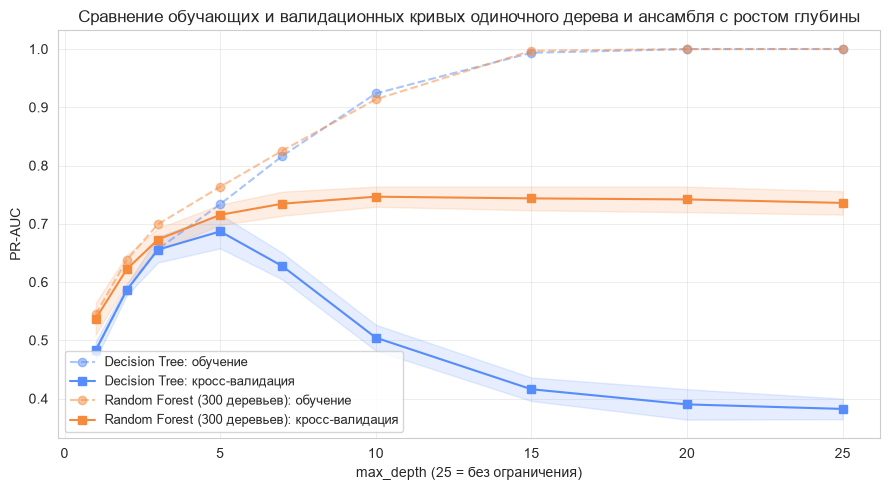

In [36]:
depths = [1, 2, 3, 5, 7, 10, 15, 20, None]
xs = [d if d is not None else 25 for d in depths]

fig, ax = plt.subplots(figsize=(9, 5))
for name, model, color in [
    ("Decision Tree", DecisionTreeClassifier(random_state=SEED), "C0"),
    (
        "Random Forest (300 деревьев)",
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
        "C1",
    ),
]:
    tr, va = validation_curve(
        make_pipe(model, variant=BEST_VARIANT, scale=False),
        X_train,
        y_train,
        param_name="clf__max_depth",
        param_range=depths,
        cv=CV_OUTER,
        scoring=MAIN_METRIC,
        n_jobs=-1,
    )
    ax.plot(xs, tr.mean(1), "o--", color=color, alpha=0.5, label=f"{name}: обучение")
    ax.plot(xs, va.mean(1), "s-", color=color, label=f"{name}: кросс-валидация")
    ax.fill_between(
        xs, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=color, alpha=0.15
    )

ax.set_xlabel("max_depth (25 = без ограничения)")
ax.set_ylabel("PR-AUC")
ax.set_title(
    "Сравнение обучающих и валидационных кривых одиночного дерева и ансамбля с ростом глубины"
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Обучающие кривые у одиночного дерева и случайного леса почти идентичны - монотонно растут и достигают максимума PR-AUC = 1.0 при глубине дерева 15, то есть обе модели полностью запоминают обучающую выборку. Валидационные кривые сильно отличаются - у одиночного дерева максимум достигается при глубине 5 (PR-AUC = ~0.69), после чего наблюдается монотонное падение до PR-AUC = ~0.38, то есть качество на новых данных ухудшается почти в два раза, у ансамблевого метода на валидации такого падения не наблюдается - кривая растет до ~0.74 и выходит на плато. Также валидационная кривая у ансамблевого метода находится выше при любой глубине дерева по сравнению с одиночным деревом.

## 9. Вложенная кросс-валидация

В блоке 8 результаты подбора гиперпараметров завышены, так как `best_score_` из `GridSearchCV` является лучшим результатом из многих попыток на одних и тех же фолдах. По этой причине в блоке 9 дополнительно проводится независимая оценка качества процесса подбора гиперпараметров. 

In [37]:
nested_rows = []
for name, (model, grid, scale) in MODELS.items():
    pipe = make_pipe(model, variant=BEST_VARIANT, scale=scale)
    search = GridSearchCV(pipe, grid, scoring=MAIN_METRIC, cv=CV_INNER, n_jobs=-1)
    res = cross_validate(
        search,
        X_train,
        y_train,
        scoring=MAIN_METRIC,
        cv=CV_OUTER,
        n_jobs=-1,
        return_estimator=True,
    )
    s = res["test_score"]

    fold_params = [est.best_params_ for est in res["estimator"]]
    cnt = Counter(tuple(sorted(p.items())) for p in fold_params)
    top, k = cnt.most_common(1)[0]

    nested_rows.append(
        {
            "модель": name,
            "вложенная CV (Average Precision)": s.mean(),
            "std по фолдам": s.std(),
            "best_score_ (из блока 8)": searches[name].best_score_,
            "смещение": searches[name].best_score_ - s.mean(),
            "устойчивость выбора": f"{k}/5 фолдов выбрали одни параметры",
            "разных наборов": len(cnt),
            "параметры финальной модели": ", ".join(
                f"{kk.replace('clf__', '')}={vv}"
                for kk, vv in sorted(searches[name].best_params_.items())
            ),
        }
    )

nested_df = pd.DataFrame(nested_rows).sort_values(
    "вложенная CV (Average Precision)", ascending=False
)
nested_df.set_index("модель").round(4)

,вложенная CV (Average Precision),std по фолдам,best_score_ (из блока 8),смещение,устойчивость выбора,разных наборов,параметры финальной модели
модель,,,,,,,
HistGradientBoosting,0.7501,0.0184,0.7476,-0.0025,5/5 фолдов выбрали одни параметры,1,"learning_rate=0.05, max_depth=6"
RandomForest,0.7454,0.0184,0.7409,-0.0046,3/5 фолдов выбрали одни параметры,3,"max_depth=20, min_samples_leaf=5"
DecisionTree,0.7064,0.0273,0.7016,-0.0048,4/5 фолдов выбрали одни параметры,2,"max_depth=7, min_samples_leaf=50"
LogReg L1,0.6868,0.0303,0.6881,0.0012,5/5 фолдов выбрали одни параметры,1,C=0.1
LogReg L2,0.6811,0.0305,0.6823,0.0013,4/5 фолдов выбрали одни параметры,2,C=10.0


Выводы по гипотезам H3 и H8 подтвердились - методы, берущие за основу деревья лучше линейной модели (H3), ансамблевые методы превосходят одиночное дерево (H8). 

Вложенная кросс-валидация показала, что результаты подбора гиперпараметров достаточно стабильные - ожидаемого завышения, возникающего при обычной кросс-валидации, не наблюдается. Смещение лучшего скора (`best_score_` из предыдущего раздела) относительно вложенной оценки лежит в диапазоне -0.0048 - +0.0013, то есть оно очень мало. Причинами такого результата может быть следующее: небольшой размер сеток для подбора гиперпараметров и меньшая доля данных, на которой обучаются модели при вложенной кросс-валидации, чем при обычной.

Устойчивость выбора гиперпараметров у разных моделей различается - у градиентного бустинга и логистической регрессии с L1 регуляризацией все 5 внешних фолдов выбрали одну и ту же конфигурацию, у решающего дерева и логистической регрессии с L2 регуляризацией - четыре из пяти, у случайного леса всего 3 из 5, причем встретилось 3 разных набора гиперпараметров. Это согласуется с валидационной кривой из раздела 8 - качество случайного леса выходит на плато по глубине и в диапазоне 10-25 различий нет, то есть выбор конкретного значения глубины определяется случайностью разбиения.

## 10. Порог классификации

ROC-AUC и PR-AUC от порога не зависят, а F1, precision и recall зависят от него, поэтому необходимо подобрать порог. Порог подбирается по out-of-fold предсказаниям на тренировочной выборке.

Финальная модель: HistGradientBoosting {'clf__learning_rate': 0.05, 'clf__max_depth': 6}


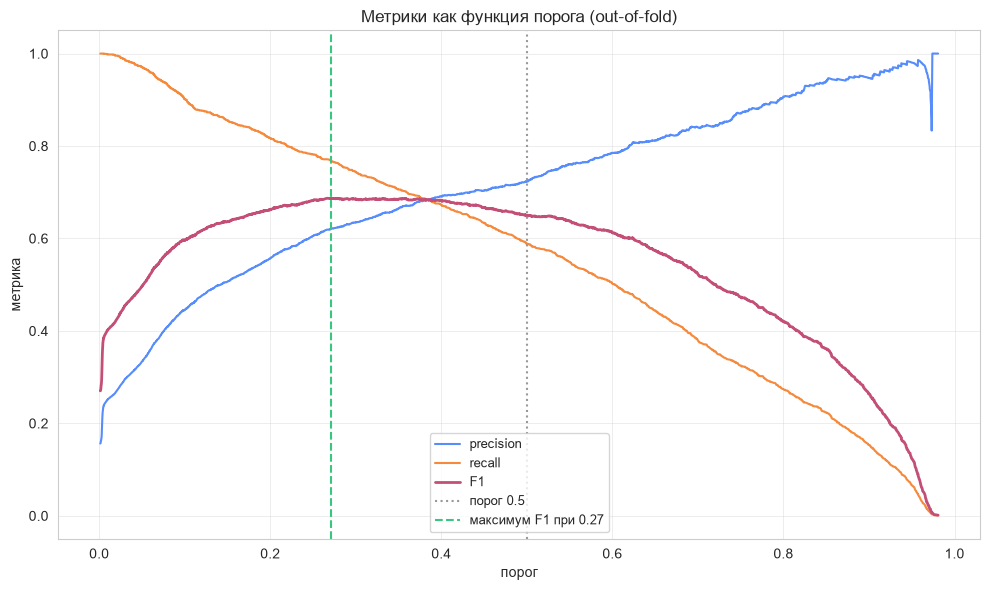

порог 0.50: precision 0.724, recall 0.588, F1 0.649
порог 0.27: precision 0.622, recall 0.769, F1 0.687


In [38]:
FINAL_NAME = nested_df.iloc[0]["модель"]
final_model = searches[FINAL_NAME].best_estimator_
print("Финальная модель:", FINAL_NAME, searches[FINAL_NAME].best_params_)

oof = cross_val_predict(
    final_model, X_train, y_train, cv=CV_OUTER, method="predict_proba", n_jobs=-1
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
best_i = int(np.nanargmax(f1s[:-1]))
BEST_THR = thr[best_i]

fig, ax = plt.subplots()
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.plot(thr, f1s[:-1], lw=2, label="F1")
ax.axvline(0.5, color="0.6", ls=":", label="порог 0.5")
ax.axvline(BEST_THR, color="C3", ls="--", label=f"максимум F1 при {BEST_THR:.2f}")
ax.set_xlabel("порог")
ax.set_ylabel("метрика")
ax.set_title("Метрики как функция порога (out-of-fold)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for t in [0.5, BEST_THR]:
    p = (oof >= t).astype(int)
    print(
        f"порог {t:.2f}: precision {precision_score(y_train, p):.3f}, "
        f"recall {recall_score(y_train, p):.3f}, F1 {f1_score(y_train, p):.3f}"
    )

Порог подобран по максимуму F1 на out-of-fold предсказаниях и составил 0.27. Кривая F1 имеет широкое плато в диапазоне порогов ~0.25 – ~0.40, поэтому конкретная точка внутри плато данными определяется слабо. В частности, точка пересечения precision и recall (порог ~0.39) дает тот же F1 = ~0.69 при другом балансе ошибок: precision и recall по 0.69 против 0.62 и 0.77 при пороге 0.27. Таким образом, выбор порога внутри плато - это выбор не качества, а соотношения цены ложной тревоги и цены пропуска; при известных стоимостях ошибок корректнее максимизировать ожидаемую прибыль, а не F1. По сравнению с порогом по умолчанию 0.50 подбор дает прирост F1 с 0.65 до 0.69 за счет роста recall с 0.59 до 0.77.

## 11. Финальная оценка на тесте

В этом разделе анализируются результаты одной лучшей выбранной модели с заранее заданным порогом.

In [39]:
final_model.fit(X_train, y_train)
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= BEST_THR).astype(int)

print(
    f"PR-AUC   {average_precision_score(y_test, proba_test):.4f}   "
    f"(случайная модель: {y_test.mean():.3f})"
)
print(f"ROC-AUC  {roc_auc_score(y_test, proba_test):.4f}")
print(f"F1       {f1_score(y_test, pred_test):.4f}")
print(
    f"accuracy {accuracy_score(y_test, pred_test):.4f}   "
    f'(константа "не купит": {1 - y_test.mean():.3f})'
)
print()
print(classification_report(y_test, pred_test, target_names=["нет покупки", "покупка"]))

# Сравнение с правилом из EDA на тех же данных
rule_test = (X_test["PageValues"] > 0).astype(int)
print(
    f"Правило PageValues > 0 на тесте: F1 {f1_score(y_test, rule_test):.4f}, "
    f"precision {precision_score(y_test, rule_test):.3f}, recall {recall_score(y_test, rule_test):.3f}"
)

PR-AUC   0.7555   (случайная модель: 0.156)
ROC-AUC  0.9351
F1       0.6782
accuracy 0.8861   (константа "не купит": 0.844)

              precision    recall  f1-score   support

 нет покупки       0.95      0.91      0.93      2059
     покупка       0.61      0.77      0.68       382

    accuracy                           0.89      2441
   macro avg       0.78      0.84      0.80      2441
weighted avg       0.90      0.89      0.89      2441

Правило PageValues > 0 на тесте: F1 0.6703, precision 0.571, recall 0.812


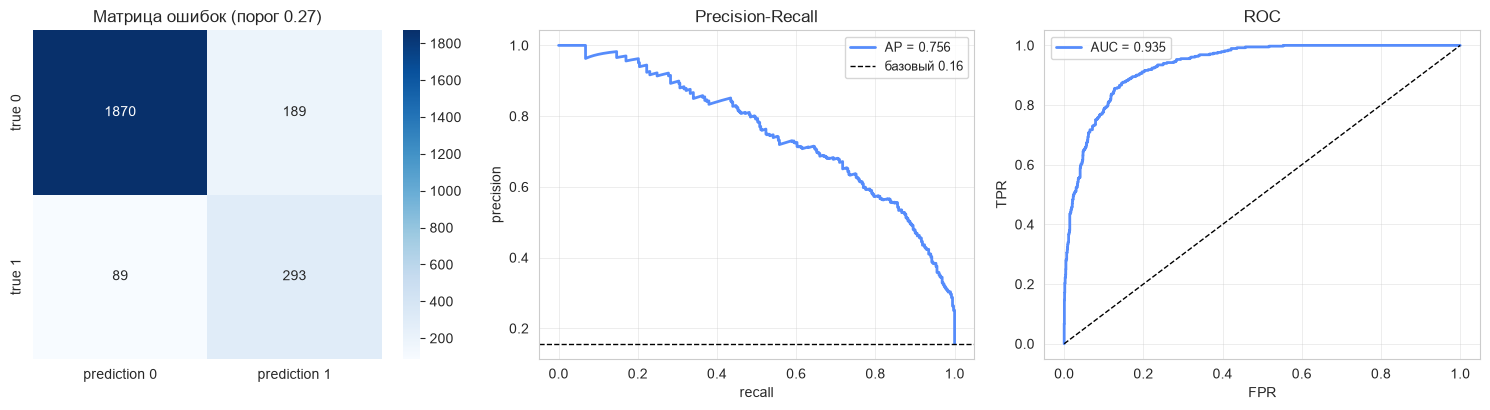

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

cm = confusion_matrix(y_test, pred_test)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["prediction 0", "prediction 1"],
    yticklabels=["true 0", "true 1"],
)
axes[0].set_title(f"Матрица ошибок (порог {BEST_THR:.2f})")

p, r, _ = precision_recall_curve(y_test, proba_test)
axes[1].plot(
    r, p, lw=2, label=f"AP = {average_precision_score(y_test, proba_test):.3f}"
)
axes[1].axhline(
    y_test.mean(), color="k", ls="--", lw=1, label=f"базовый {y_test.mean():.2f}"
)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-Recall")
axes[1].legend(fontsize=9)

fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[2].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, proba_test):.3f}")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].set_title("ROC")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

В качестве итоговой модели был выбран HistGradientBoosting с порогом 0.27.

Average Precision на тесте составила 0.7555, на вложенной кросс-валидации метрика равнялась 0.750. Разница в метриках составляет всего 0.005, что находится внутри стандартного отклонения по фолдам (0.018). То есть, схема валидации смогла воспроизвести похожее качество на данных, которые модель не видела ни на одном этапе, а значит, что утечек в пайплайне нет. Выбор модели, гиперпараметров и порога не привел к переобучению на обучающей выборке.

Average Precision получившейся модели превосходит эту же метрику случайной модели почти в 5 раз (0.7555 vs 0.156).

У константного предсказания "не купит" accuracy ниже, чем у итоговой модели (0.844 vs 0.886), прирост у итоговой модели по сравнению с константой всего 4.2%, что опять же подтверждает непригодность accuracy как основной метрики при таком дисбалансе данных.

Между метриками ROC-AUC и PR-AUC наблюдается сильный разрыв (0.935 vs 0.756), что опять же характерно для несбалансированных данных. ROC-AUC учитывает долю ложных тревог относительно 2059 отрицательных объектов, поэтому 189 ошибок почти не влияют на эту метрику; precision же считается от 482 предсказанных покупок, и те же 189 ошибок снижают метрику до 0.61. 

Матрица ошибок показывает следующее: из 382 реальных покупок модель нашла 293 (recall = 0.77) и пропустила 89. Из 482 сессий, помеченных как покупка, верными оказались 293 (precision = 0.61), ложных срабатываний 189. По отрицательному классу модель показывает высокое качество: precision = 0.95, recall = 0.91.

Сравнение с бейзлайном показывает, что правило "`PageValues` > 0" даёт на тесте F1 = 0.6703 против 0.6782 (F1 положительного класса) у модели, то есть преимущество всего 0.8%. При этом структура ошибок различается: правило имеет более высокий recall (0.812 vs 0.767 - то есть простое правило по одному признаку находит 81% всех покупок) и более низкую precision (0.571 vs 0.608). То есть весь пайплайн почти не превзошел бейзлайн. Однако это не означает, что модель бесполезна. Правило выдает только два возможных ответа и работает в единственной точке, в то время как модель ранжирует сессии по вероятности покупки. PR-кривая показывает, что при recall = ~0.45 precision превышает 0.8, а при recall = ~0.9 precision падает ниже 0.4. То есть модель позволяет выбрать порог под конкретную цену ошибки, чего невозможно достичь правилом.

## 12. Важность признаков (H1, H5)

В этом блоке оценивается, на какие признаки опирается итоговая модель, и проверяется оставшаяся часть гипотез H1 и H5.

Важность измеряется методом перестановок (permutation importance): значения одного признака случайным образом перемешиваются между строками, после чего заново считается PR-AUC на тесте. Чем сильнее падает метрика, тем больше модель опиралась на этот признак.

Важность считается в двух разрезах, и они отвечают на разные вопросы. По исходным признакам перемешивается целиком колонка исходной таблицы - например, весь `Month` сразу; этот разрез показывает вклад признака как источника данных. По колонкам после предобработки перемешиваются отдельные закодированные колонки - например, только `Month_Nov`; этот разрез показывает, какие именно значения признака важны модели.

Отдельно проверяется устойчивость отбора признаков: модель обучается на множестве бутстрап-выборок, и для каждого признака считается доля выборок, в которых L1-регуляризация оставила его в модели. Это нужно для проверки той части H5, которая утверждает, что замена базиса делает отбор признаков воспроизводимым.

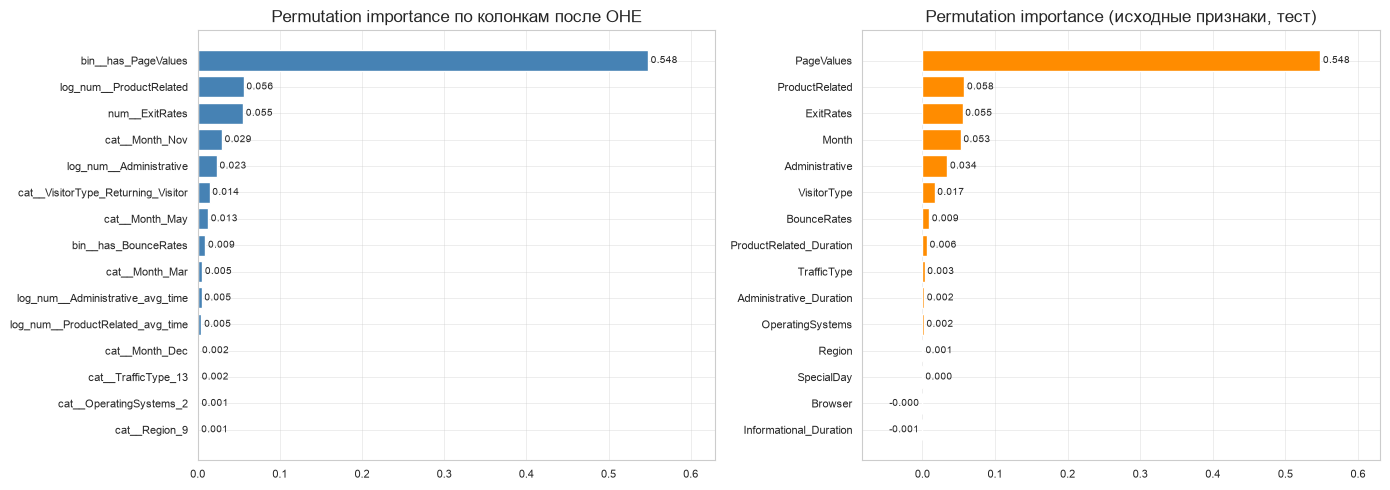

In [41]:
names_final = np.array(final_model["prep"].get_feature_names_out())
clf = final_model["clf"]
Z_test = final_model[:-1].transform(X_test)

if hasattr(clf, "feature_importances_"):
    built_in = pd.Series(clf.feature_importances_, index=names_final)
    built_in_title = "Встроенная важность (колонки после OHE)"
elif hasattr(clf, "coef_"):
    built_in = pd.Series(np.abs(clf.coef_[0]), index=names_final)
    built_in_title = "|коэффициент| (колонки после OHE)"
else:
    built_in = pd.Series(
        permutation_importance(
            clf,
            Z_test,
            y_test,
            scoring=MAIN_METRIC,
            n_repeats=10,
            random_state=SEED,
            n_jobs=-1,
        ).importances_mean,
        index=names_final,
    )
    built_in_title = "Permutation importance по колонкам после OHE"

perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring=MAIN_METRIC,
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(
    ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_b = built_in.sort_values(ascending=False).head(15).iloc[::-1]
b1 = axes[0].barh(top_b.index, top_b.values, color="steelblue")
axes[0].bar_label(b1, fmt="%.3f", fontsize=7, padding=2)
axes[0].set_title(built_in_title)

top_p = perm_s.head(15).iloc[::-1]
b2 = axes[1].barh(top_p.index, top_p.values, color="darkorange")
axes[1].bar_label(b2, fmt="%.3f", fontsize=7, padding=2)
axes[1].set_title("Permutation importance (исходные признаки, тест)")

for ax in axes:
    ax.tick_params(labelsize=8)
    ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Оба разреза согласованно показывают один доминирующий признак. Вклад `PageValues` составляет 0.548, что почти в десять раз больше, чем у следующего признака (`ProductRelated`, 0.058).

Важно отметить, что в итоговом наборе признаков (`all`) используется не числовое значение `PageValues`, а бинарный признак `has_PageValues`, который показывает, было ли значение `PageValues` больше нуля. Это объясняет результаты на графиках: важность `has_PageValues` слева равна 0.548 и совпадает с важностью исходного `PageValues` справа. Причина в том, что генерация признаков выполняется внутри пайплайна: при перемешивании `PageValues` пересчитывается и зависящий от него бинарный признак. То есть для предсказания покупки достаточно знать сам факт ненулевой ценности посещенных страниц, а ее величина дополнительного вклада не дает - это **уточняет формулировку H1**: наиболее информативным оказался не `PageValues` как числовая величина, а признак его ненулевого значения.

Сравнение двух частей графика показывает, почему важность категориальных признаков распределяется по-разному. Например, в правой части графика признак `Month` имеет важность 0.053 и занимает четвертое место. В левой части он представлен отдельными признаками для каждого месяца: `Month_Nov` - 0.029, `Month_May` - 0.013, `Month_Mar` - 0.005 и `Month_Dec` - 0.002. Их суммарная важность составляет примерно 0.049, что близко к значению для `Month` справа. При этом разбиение по месяцам позволяет увидеть, какие именно месяцы наиболее важны для предсказания покупки. Самый значимый из перечисленных - ноябрь (`Month_Nov`), что согласуется с результатами EDA о повышенной активности покупателей в период Черной пятницы.

При перемешивании исходного признака `Administrative` меняются сразу два признака, которые использует модель: количество административных страниц (`log_num__Administrative`, важность 0.023) и среднее время на просмотр одной такой страницы (`Administrative_avg_time`, важность 0.005). Это связано с тем, что количество страниц используется не только напрямую, но и при расчете среднего времени - оно стоит в знаменателе формулы. Поэтому важность `Administrative` в правой панели (0.034) отражает влияние исходного признака сразу на оба признака модели. В отличие от него, `Administrative_Duration` влияет только на `Administrative_avg_time`, поскольку сама длительность в модель не передается. Этим объясняется ее низкая важность (0.002). При этом значения на двух панелях нельзя напрямую складывать или сравнивать арифметически: важности не являются аддитивными. В правой панели влияние производного признака `Administrative_avg_time` учитывается и при оценке `Administrative`, и при оценке `Administrative_Duration`.

Результаты еще раз подтверждают **H2**: у `Browser` важность отрицательна (−0.000), у `OperatingSystems` и `Region` она составляет 0.002 и 0.001, то есть неотличима от нуля. Значимыми из категориальных остались `Month` (0.053) и `VisitorType` (0.017). При этом `TrafficType` с важностью 0.003 оказался заметно слабее, чем ожидалось по результатам EDA, где он выглядел самым информативным категориальным признаком. Это объясняется тем, что в модели используется не одномерная связь признака с таргетом, а его влияние вкупе с другими признаками.

Отрицательные и нулевые значения получили `Browser`, `Informational_Duration` (−0.001) и `SpecialDay` (0.000). Отрицательная важность означает, что после перемешивания качество модели слегка выросло, то есть признак вносит только шум. Для `SpecialDay` это подтверждает ожидание, сформулированное по боксплотам еще на этапе EDA .

In [42]:
N_BOOT = 200
rng = np.random.default_rng(SEED)
n = len(X_train)
BOOT_IDX = [rng.integers(0, n, n) for _ in range(N_BOOT)]
Xf_tr = add_features(X_train)


def boot_selection_freq(variant, C=0.1):
    prep = make_preprocessor(variant)
    Z = prep.fit_transform(Xf_tr)
    counts, yv = np.zeros(Z.shape[1]), y_train.values
    for idx in BOOT_IDX:
        m = LogisticRegression(
            penalty="l1", solver="liblinear", C=C, max_iter=5000
        ).fit(Z[idx], yv[idx])
        counts += np.abs(m.coef_[0]) > 1e-8
    return pd.Series(counts / N_BOOT, index=prep.get_feature_names_out())


def pick(freq, short):
    hits = [c for c in freq.index if c.split("__")[-1] == short]
    return float(freq[hits[0]]) if hits else np.nan


freq_before = boot_selection_freq("log+flags")  # пары (Count, Duration)
freq_after = boot_selection_freq("basis")  # пары (Count, Duration / Count)

rows = []
for c in COUNT_COLS:
    rows.append(
        {
            "пара": c,
            "признак": f"счетчик {c}",
            "до замены": pick(freq_before, c),
            "после замены": pick(freq_after, c),
        }
    )
    rows.append(
        {
            "пара": c,
            "признак": f"{c}_Duration -> {c}_avg_time",
            "до замены": pick(freq_before, f"{c}_Duration"),
            "после замены": pick(freq_after, f"{c}_avg_time"),
        }
    )

tbl = pd.DataFrame(rows).set_index(["пара", "признак"]).round(2)
tbl["ушел из зоны 0.4–0.6"] = np.where(
    tbl["до замены"].between(0.4, 0.6) & ~tbl["после замены"].between(0.4, 0.6),
    "да",
    np.where(tbl["после замены"].between(0.4, 0.6), "нет", "---"),
)

display(tbl)

for nm, f in [("до замены", freq_before), ("после замены", freq_after)]:
    print(
        f"{nm}: признаков в зоне 0.4–0.6 --- {int(f.between(0.4, 0.6).sum())} из {len(f)}"
    )

до замены  после замены ушел из зоны 0.4–0.6
пара           признак                                                                                         
Administrative счетчик Administrative                                   0.88          1.00                  ---
               Administrative_Duration -> Administrative_avg_time       0.85          0.70                  ---
Informational  счетчик Informational                                    0.50          0.57                  нет
               Informational_Duration -> Informational_avg_time         0.67          0.69                  ---
ProductRelated счетчик ProductRelated                                   0.50          0.62                   да
               ProductRelated_Duration -> ProductRelated_avg_time       0.39          0.60                  нет

до замены: признаков в зоне 0.4–0.6 --- 7 из 61
после замены: признаков в зоне 0.4–0.6 --- 7 из 61


В этом раздлеле была проверена часть гипотезы **H5**, утверждающая, что замена базиса делает отбор признаков воспроизводимым. Частота - это доля из 200 бутстрап-выборок, в которых L1-регуляризация оставила признак в модели. Значения около 0.5 означают, что отбор признака определяется случайностью выборки, а не данными; значения, близкие к 0 или 1, дают определенный ответ.

В целом гипотеза подтвердилась лишь частично: эффект замены базиса различался для разных пар признаков, а устойчивость отбора по модели в целом не улучшилась.

Пара `Administrative` оказалась устойчивой еще до преобразования, вопреки первоначальному ожиданию. Несмотря на высокую корреляцию (0.924), оба признака отбирались достаточно стабильно: частота отбора счетчика составляла 0.88, а производного признака - 0.85. После замены базиса счетчик стал отбираться во всех бутстрап-выборках (1.0), а частота отбора производного признака снизилась до 0.7. Однако оба значения находятся далеко от зоны неопределенности. Следовательно, высокая корреляция не обязательно приводит к нестабильному отбору признаков.

Для пары `ProductRelated` улучшение было более заметным, но ограниченным. После замены базиса частота отбора счетчика выросла с 0.50 до 0.62, а производного признака - с 0.38 до 0.60. Оба признака стали отбираться чаще, однако результат для производного признака остался на границе зоны неопределенности. Именно у этой пары замена базиса сильнее всего снизила корреляцию - с 0.852 до 0.415. Таким образом, изменения согласуются с ожиданием, но не свидетельствуют о существенном повышении устойчивости отбора.

Для пары `Informational` заметного улучшения не произошло. Частота отбора счетчика увеличилась лишь с 0.50 до 0.57 и осталась в зоне неопределенности. Это согласуется с результатами раздела 6: корреляция после замены базиса снизилась незначительно - с 0.916 до 0.860. Вероятное объяснение заключается в большом количестве нулевых значений, из-за которого преобразование слабее меняет структуру зависимости между признаками.

На уровне всей модели устойчивость отбора не улучшилась: и до, и после замены базиса в зоне частот 0.4–0.6 находились 7 из 61 признака.

Причину такого результата помогает понять график permutation importance выше. Производные признаки `Administrative_avg_time` и `ProductRelated_avg_time` имеют важность около 0.005, то есть их вклад в предсказания невелик. Замена базиса уменьшила корреляцию между признаками, но не повысила их информативность. Если признак почти не влияет на качество предсказания, модель может включать его в одних бутстрап-выборках и исключать в других. Поэтому устранение мультиколлинеарности само по себе не гарантирует воспроизводимого отбора: важна также информативность самих признаков.

**Итог по H5: гипотеза подтвердилась частично.** Замена базиса снизила корреляцию внутри рассмотренных пар, особенно для `ProductRelated`, но не привела к заметному повышению устойчивости отбора по модели в целом. Качество предсказания при этом не изменилось, что согласуется с предположением об отсутствии дополнительной информации после преобразования.

## 13. Выводы по гипотезам

Для каждой гипотезы указан измеренный результат и вердикт. Критерий значимости во всех экспериментах один: разница считается реальной, если она превышает стандартное отклонение метрики по фолдам.

| # | Гипотеза                                                                                           | Где проверялась | Результат                                                                                                                                                                                                                                                                                             | Статус                     |
|---|----------------------------------------------------------------------------------------------------|---|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|----------------------------|
| H1 | `PageValues` — самый информативный признак                                                         | 7, 12 | наибольший по модулю коэффициент в RFE-модели; permutation importance 0.548 против 0.058 у следующего признака (`ProductRelated`)                                                                                                                                                                     | подтвердилась с уточнением |
| H2 | Значимы только `TrafficType`, `Month`, `VisitorType`; дамми-колонки `Region` и `Browser` удаляются | 7 | значимость подтвердилась: в `Month` осталось 6 из 10 колонок, в `TrafficType` 7 из 12, в `VisitorType` 1 из 3. Но `Region` (осталась 1 из 9 колонок) и `Browser` (3 из 8) не удалились полностью, в `OperatingSystems` осталось 4 из 5 колонок                                                        | подтвердилась частично     |
| H3 | Деревянные модели обходят логистическую регрессию                                                  | 9 | HistGradientBoosting показал Average Precision = 0.7501 при std = 0.0184 против LogReg L1 AP = 0.6868, std = 0.0302: разница +0.063 больше std. Однако одиночное дерево (AP = 0.7064) превосходит логистическую регрессию лишь на 0.020 при std 0.027–0.030                                           | подтвердилась частично     |
| H4 | `log1p` улучшает PR-AUC логрегрессии и не меняет дерево                                            | 5 | логистическая регрессия улучшается с 0.6360 до 0.6828 (+0.047 при std 0.022, улучшение вдвое больше разброса); дерево - с 0.6751 до 0.6746 (разница −0.0005) - разница минимальна                                                                                                                     | подтвердилась              |
| H5 | Замена базиса устраняет мультиколлинеарность, не меняя качества, и делает отбор воспроизводимым    | 5, 6, 12 | корреляция внутри паруменьшилась: 0.852 -> 0.415 (`ProductRelated`), 0.924 -> 0.808 (`Administrative`), 0.916 -> 0.860 (`Informational`). Качество не изменилось: AP = 0.6948 -> 0.6946. Устойчивость отбора не выросла: 7 признаков из 61 в зоне 0.4–0.6 (эффект случайный) до и после замены базиса | подтвердилась частично     |
| H6 | Бинаризация признаков `PageValues`, `Informational`, `SpecialDay` дает прирост качества            | 5 | AP = 0.6828 -> 0.6948 (+0.012 при std 0.024): направление верное, но эффект меньше разброса по фолдам                                                                                                                                                                                                 | подтвердилась частично     |
| H7 | Бинаризация признака `BounceRates` снижает корреляцию с `ExitRates`                                | 5, 6 | корреляция 0.90 -> 0.324; качество не пострадало (AP = 0.6948 -> 0.6973)                                                                                                                                                                                                                              | подтвердилась              |
| H8 | Ансамбль лучше одиночного дерева                                                                   | 9 | HistGradientBoosting AP = 0.7501 и RandomForest AP = 0.7454 против DecisionTree AP = 0.7064: разница +0.044 и +0.039 при std 0.018–0.027                                                                                                                                                              | подтвердилась              |

Статус гипотезы **подтвердилась** означает, что эффект наблюдается в предсказанную сторону и превышает std по фолдам; **частично** - направление верное, но величина меньше заявленной, либо подтвердилась лишь часть утверждения.

### Уточнения к отдельным гипотезам

**H1.** Наиболее информативным оказался не `PageValues` как числовая величина, а бинарный признак `has_PageValues`. В итоговом наборе признаков сама величина отсутствует, и ее исключение не ухудшило качество, то есть для предсказания покупки достаточно факта ненулевой ценности посещенных страниц.

**H3.** Преимущество дают не деревянные модели как класс, а ансамблирование: одиночное дерево от логистической регрессии статистически неотличимо. Дополнительный аргумент дает эксперимент 1: на непреобразованных данных дерево обходило логистическую регрессию (0.675 против 0.636), а после логарифмирования логистическая регрессия вышла вперед (0.683 против 0.675). Часть преимущества деревьев объяснялась тем, что дерево само нелинейно преобразует шкалу признаков.

**H5.** Эффект замены базиса зависит от доли нулей у счетчика: наибольшее снижение корреляции получено для `ProductRelated` (доля нулей = 0.05), наименьшее - для `Informational` (доля нулей = 0.8). У признаков с преобладанием нулей корреляция порождается совпадением нулевых значений, и отношение `Duration / Count` ее не устраняет, поскольку наследует ту же точечную массу.

**H6.** Прирост последовательный, но по заранее заданному критерию недостаточный. При этом флаг `has_PageValues` получил вторую по величине важность в итоговой модели: признак активно используется, но несет ту же информацию, что и логарифм, поэтому нового качества не добавляет.